# 10 · Summary statistics from skewers

The summary statistics of the flux, built bottom-up on toy boxes whose statistics are known. The toy fields and their
statistics are introduced and validated in notebook 08; here they are only generated.

**Overview.**

- **Part A — skewers:** a regular lattice of skewers along $y$ through every box, step by step (`SkewerBundle`,
  cells, pieces, $\tau$); $\tau$ of the lines of `LINE_IDS` ($\mathrm{Ly}\alpha$, Si III 1206, Si II 1193, Si II 1190), periodic.
- **Part B — the same statistics of the density** on the same skewers as the overfluxes of Part D, figure by figure,
  against their exact expectation.
- **Part C — transmission and overflux:** the normalisation and one skewer from the gas to the overflux.
- **Part D — summary statistics of the overfluxes:** the bins and the statistics (D1); in 3D on the lattice of skewers,
  the $(k_\perp, k_\parallel)$ and $(r_\perp, r_\parallel)$ planes, $P$ and $r^2\xi$, the wedges of $\mu$ (D2, D3); in 1D,
  P1D next to a measurement, order by order and term by term (D4 to D6).

In [27]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)
import time
import numpy as np, jax, jax.numpy as jnp
# float32, the package's precision; skewerjax.config.set_precision("float64") for float64 (docs/precision.md)
import matplotlib.pyplot as plt
from skewerjax.utils.plotting import use_style, use_backend
use_backend()
use_style()
from skewerjax.utils.plotting import DIM, add_panel_letters, plot_overflux_kpar_kperp, plot_overflux_rpar_rperp, plot_xi_mu_wedges
from skewerjax.core import LineBundle, SkewerBundle, phys
from skewerjax.simulations import ToyBoxes
from skewerjax.summary_stats import bao_k_edges, lattice_grid

In [2]:
REALISATIONS = None
L_BOX = 320
LINE_IDS = ("HI-LyA", "SiIII-1206") # "SiII-1193", "SiII-1190"
METAL_TO_HI = {"SiIII": 1 / 10} # "SiII": 1 / 20               # n_X = r_X n_HI: Si III as before; Si II an illustrative toy choice, half of Si III
boxes = ToyBoxes(box_cMpc=L_BOX, n_s = -0.4, n_cells=320, n_real=2, base_seed=137, bao_ratio=0.0008, sigma_bao=1.0, r_bao=147, metal_to_hi=METAL_TO_HI, velocity="linear", z = 2.0)

In [3]:
idx = np.arange(boxes.n_real) if REALISATIONS is None else np.asarray(REALISATIONS)
L, dx = boxes.box_cMpc, boxes.dx
K_EDGES, K_INFO = bao_k_edges(2 * np.pi / L, np.pi / dx, 3.0 / boxes.sigma_bao, k_1=None, dk_factor=0.4, n_log=12, info=True)  # |k|: per mode to k_1, dk_factor k_f to k_2 = 3 / sigma_BAO, log to pi / dx
R_EDGES = np.arange(0, L / 2 + dx, dx)                  
fields0 = boxes.fields(0)# |r| (and the mu wedges, the r_perp columns): width dx to L / 2

## Part A — Skewers

### A1 · Skewers through each box

**Layout.** In every box, skewers run along $y$ through the centres of the cell columns (the nodes $x = i_x\,dx$,
$z = i_z\,dx$ of `grf_cells`), from $y = 0$ to $y = L$, so their first and last points are the same place of the periodic
box.

**The set-up**, with $p$ = `POINTS_PER_CELL` and
$N_{\rm pix}$ = `N_PIX`:

| Argument | What it controls | Result or cost |
|---|---|---|
| `STRIDE` $= (s_x, s_z)$ | the cell columns that become skewers: every $s_x$-th in $x$ and every $s_z$-th in $z$, from column 0, exactly through the cell centres $x = i\,s_x\,dx$, $z = j\,s_z\,dx$; $\lceil N/s_x\rceil \lceil N/s_z\rceil$ skewers per box, $s\,dx$ apart | the number of skewers and the transverse sampling; the cost is linear in the number of skewers |
| `POINTS_PER_CELL` | $p$, the points of the path per cell length along $y$, $N p + 1$ per skewer: every cell is cut into pieces of width $W = dx/p$ | the result until it converges (accurate while $W \ll b$); the cost of $\tau$ is linear in $p$ |
| `N_PIX` | $N_{\rm pix}$ velocity pixels over one period, of width $dv = v_{\rm per}/N_{\rm pix}$: the velocity resolution | the result: the $k$ range of P1D, up to $\pi/dv$, and the LoS resolution of Part D; the cost of $\tau$ is linear in $N_{\rm pix}$ |

Here $v_{\rm per}$ is the velocity span of one box along a skewer, and $u = v_{\rm per}/L$ converts comoving distances to
velocities.


- **The drift along $v$.** The skewers are in the exact frame: $z$ sits at $y = 0$ and $a(y)$ decreases along the box,
  by $\Delta\ln a = v_{\rm per}/c$, while the box is wrapped as periodic. A uniform gas then has
  $\tau \propto a^{-2}/(aH)$ per pixel, varying across the box, so $\bar T(v)$ drifts and
  jumps back at the wrap. It comes from the factor $a(y)^{-2}$ and from the Jacobian $1/(aH(y))$: `A_EFF` removes the
  first, `HUBBLE_FLOW = "linear"` the second. `"redshift"` removes that drift from $\delta$; with `"global"` it stays as a pattern shared by
  every skewer, which shows as horizontal bands in the $(r_\perp, r_\parallel)$ map (D2).
- **The density conversion, `A_EFF = 1/(1+z)`.** `compute_optical_depth(a_eff=)` replaces $a_p^{-2}$ of every piece by
  one $a_{\rm eff}^{-2}$: one fixed comoving-to-physical conversion at the box redshift ($z$ at $y = 0$; `None` keeps
  $a(y)^{-2}$ per piece). It touches nothing else. With `HUBBLE_FLOW = "exact"` the line centres keep $c\ln(a_0/a(y))$, so a column still spreads
  over a velocity width $\propto aH\,\ell$: the Jacobian $1/(aH)$ of the frame remains, about $-1.8$ % across the box
  ($aH$ grows with $z$).
- **The detuning, `DETUNING = "linear"`.** fake_spectra's first-order mapping of $v - v_c$ to a frequency offset in
  the line profile. It changes $\tau$ by less than $10^{-5}$, and it does not linearise the line centres
  $c\ln(a_0/a(y))$ of the exact frame.
- **The Hubble flow, `HUBBLE_FLOW = "exact"`.** A piece at path coordinate $y_p$ absorbs at line centre
  $v_{c,p} = V_H(y_p) + v_{{\rm pec},p}$. `"exact"` follows the frame, $V_H(y) = c\ln(a_0/a(y)) = \int_0^y aH\,dy'$:
  the line centres are spaced by $aH(y)$, which grows along the box, so a column spreads over a velocity width that
  varies (the Jacobian $1/(aH)$), and $v_{\rm per} = c\ln(a(0)/a(L))$. `"linear"` is fake_spectra's Hubble flow,
  $V_H(y) = (aH)_{\rm ref}\,y$ with $(aH)_{\rm ref}$ at $z$ ($y = 0$): uniform spacing, a constant Jacobian and
  $v_{\rm per} = (aH)_{\rm ref}L$. The two differ at second order, $V_H - (aH)_{\rm ref}y \simeq \tfrac12 (aH)'\,y^2$,
  108 km/s over one box. Together with `A_EFF = 1/(1+z)` and `DETUNING = "linear"`, `"linear"` is fake_spectra's
  model of one snapshot; what remains is numerical (fake_spectra averages each profile over the pixel and over the
  cell's segment, while here it is evaluated at the pixel centre and each piece at its centroid).

In [4]:
from skewerjax.core import bundle_frame, compute_optical_depth, velocity_span
from skewerjax.core.absorbers import cell_pieces
from skewerjax.core import hubble_velocity, lattice_columns, lattice_points
from skewerjax.summary_stats import lattice_limits

In [5]:
LINES = LineBundle(list(LINE_IDS), ref_line_id=LINE_IDS[0])  # line 1, the reference: Lyα
STRIDE, POINTS_PER_CELL, N_PIX, BATCH = (2, 2), 16, 320, 320 # the table above
A_EFF = 1 / (1 + boxes.z)                                    # one comoving-to-physical density conversion, at the box redshift (z at y = 0); None: a(y)^-2 per piece
DETUNING = "linear"                                          # first-order mapping of v - v_c to a frequency offset
HUBBLE_FLOW = "linear"                                       # "exact": c ln(a0/a(y)); "linear": (aH)_ref y

COLS = lattice_columns(boxes.n_cells, STRIDE)                     # (N_sk, 2) the cell columns (i_x, i_z) of the skewers, x-major
BATCHES = [COLS[b:b + BATCH] for b in range(0, len(COLS), BATCH)] # BATCH skewers per call: the memory only
FRAME_KW = dict(cosmologies=boxes.cosmology(), a0=1/(1 + boxes.z), x0=L, ICs_defined_at_index=-1)  # the exact frame: z at y = 0, the first point
BUNDLE = SkewerBundle(spatial_points=lattice_points(BATCHES[0], dx, L_BOX, boxes.n_cells, POINTS_PER_CELL), **FRAME_KW)  # the SkewerBundle of the lattice (its first batch): paths and frame

FRAME = bundle_frame(BUNDLE)                                      # the exact frame: a0 = 1 / (1 + z) at y = L, a(y) along the path
PERIOD = float(velocity_span(BUNDLE, HUBBLE_FLOW)[0])             # v_per [km/s], one box: the span of the line centres, c ln(a(0)/a(L)) ("exact") or (aH)_ref L ("linear"); not DETUNING
V = (np.arange(N_PIX) + 0.5) * PERIOD / N_PIX                     # the velocity grid: N_PIX pixel centres over the period (Lyα axis)

In [6]:
DV = PERIOD / N_PIX
A_PIX = FRAME.a_dagger * np.exp(-V / phys.c_kms)                  # the scale factor of every pixel: the redshift grid of the mean
u = PERIOD / L_BOX                                                # km/s per cMpc: v = u x, k_v = k_x / u
D_PERP = np.array(STRIDE) * boxes.dx                              # the transverse spacing of the skewers [cMpc]
n_x, n_z = (boxes.n_cells // s for s in STRIDE)
lim = lattice_limits(L_BOX, D_PERP, N_PIX, PERIOD)                # the lattice of Part D: exactly the skewers' samples
v_c, y_pts = hubble_velocity(BUNDLE), np.asarray(BUNDLE.spatial_points)[0, :, 1]   # the line centres along one skewer
print(f"skewers: stride {STRIDE} -> {n_x} x {n_z} = {len(COLS)} per box, {len(COLS) * idx.size} in all ({idx.size} boxes), in {len(BATCHES)} batches of {BATCH}")
print(f"transverse spacing of the skewers: stride x dx = {STRIDE[0]} x {boxes.dx:.4g} = {D_PERP[0]:.4g} cMpc in x")
print(f"SkewerBundle: frame a0 = {float(FRAME.a_dagger):.5f} = 1 / (1 + z) at y = 0 (z = {boxes.z:g}), a(L) = {float(np.asarray(BUNDLE.scale_factors)[0, 0, -1]):.5f}; {y_pts.size} points per skewer ({POINTS_PER_CELL} per cell)")
print(f"pieces of W = {boxes.dx / POINTS_PER_CELL:.4f} cMpc = {PERIOD / (boxes.n_cells * POINTS_PER_CELL):.3f} km/s")
print(f"pixels: {N_PIX} over v_per = {PERIOD:.0f} km/s: dv = {DV:.2f} km/s, P1D up to pi / dv = {np.pi / DV:.4f} s/km")

skewers: stride (2, 2) -> 160 x 160 = 25600 per box, 51200 in all (2 boxes), in 80 batches of 320
transverse spacing of the skewers: stride x dx = 2 x 1 = 2 cMpc in x
SkewerBundle: frame a0 = 0.33333 = 1 / (1 + z) at y = 0 (z = 2), a(L) = 0.33333; 5121 points per skewer (16 per cell)
pieces of W = 0.0625 cMpc = 4.524 km/s
pixels: 320 over v_per = 23164 km/s: dv = 72.39 km/s, P1D up to pi / dv = 0.0434 s/km


**$\tau$, box by box.** Each box is generated from its seed and `compute_optical_depth` sums them into $\tau$.
Only $\tau$ and the densities of the cells the skewers cross are kept.

In [7]:
import warnings
from tqdm.auto import tqdm

TAU, DENS, RES, T_BOX = [], [], [], []   # tau (N_lines, N_sk, N_PIX) per box, the gas the lattice crosses, resolution checks, timings
t0 = time.perf_counter()
bar = tqdm(total=len(idx), desc="boxes") if tqdm else None
with warnings.catch_warnings(record=True) as WARN:               # the resolution check of compute_optical_depth (counted below)
    warnings.simplefilter("always")
    for n_done, i in enumerate(idx, start=1):
        t_f = time.perf_counter()
        fields_i = boxes.fields(int(i))                          # the gas of realisation i on the grid
        cells = boxes.cells(int(i), fields_i)                    # -> core.Cells
        t_f, t_p, t_t, tau_i = time.perf_counter() - t_f, 0.0, 0.0, []
        for cols_b in BATCHES:
            t1 = time.perf_counter()
            bundle = SkewerBundle(spatial_points=lattice_points(cols_b, dx, L_BOX, boxes.n_cells, POINTS_PER_CELL), **FRAME_KW)  # the paths of the batch
            pieces = cell_pieces(cells, LINES, skewer_bundle=bundle)  # cells -> pieces
            t2 = time.perf_counter()
            tau_b, info = compute_optical_depth(  # CALCULATION OF THE OPTICAL DEPTH tau
                pieces, V, LINES, velocity_period=True, line_frame="reference", a_eff=A_EFF, detuning=DETUNING, hubble_flow=HUBBLE_FLOW, return_info=True
            )
            tau_i.append(np.asarray(tau_b))
            RES.append(np.stack([info["resolution"]["max_ratio"], info["resolution"]["column_fraction"]], -1))
            t_p, t_t = t_p + t2 - t1, t_t + time.perf_counter() - t2
        TAU.append(np.concatenate(tau_i, axis=1))
        DENS.append({sp: n[::STRIDE[0], :, ::STRIDE[1]] for sp, n in fields_i["n"].items()})  # the cells the lattice crosses
        T_BOX.append((t_f, t_p, t_t))
        del fields_i, cells
        elapsed = time.perf_counter() - t0
        msg = (f"box {n_done}/{len(idx)} · fields {t_f:.1f} s · pieces {t_p:.1f} s · τ {t_t:.0f} s · elapsed {elapsed:.0f} s · "
               f"ETA {elapsed / n_done * (len(idx) - n_done):.0f} s")

        bar.set_postfix_str(msg.split(" · ", 1)[1])
        bar.update()
bar.close()

boxes:   0%|          | 0/2 [00:00<?, ?it/s]

In [8]:
from skewerjax.utils.plotting import line_names
NAMES_L = line_names(LINE_IDS)                                   # Lyα, Si III, Si II 1193, Si II 1190
TAU, T_BOX, RES = np.stack(TAU), np.array(T_BOX), np.array(RES)  # TAU (n_box, N_lines, N_sk, N_PIX)
t_skewers = time.perf_counter() - t0
n_box, n_sk = TAU.shape[0], TAU.shape[2]
b_T0 = {lid: np.sqrt(2 * phys.kB * boxes.T0 / m) / 1e3 for lid, m in zip(LINE_IDS, np.asarray(LINES.mass_amu))}
print(f"{n_box} boxes x {n_sk} skewers ({n_x} x {n_z}) in {t_skewers:.0f} s")
print(f"time per box: fields {T_BOX[:, 0].mean():.1f} s, pieces {T_BOX[:, 1].mean():.1f} s, tau {T_BOX[:, 2].mean():.0f} s")
print(f"axis: period {PERIOD:.0f} km/s, {N_PIX} pixels of dv = {DV:.2f} km/s; a cell spans "
      f"{PERIOD / boxes.n_cells:.1f} km/s ({N_PIX / boxes.n_cells:g} pixels), a piece {PERIOD / boxes.n_cells / POINTS_PER_CELL:.2f} "
      f"km/s; b at T0: " + ", ".join(f"{lid} {b:.1f} km/s" for lid, b in b_T0.items()))
print(f"resolution check: max W / b = {np.round(RES[..., 0].max(axis=0), 3)}, column fraction above b/4 at most "
      f"{np.round(RES[..., 1].max(axis=0), 6)} ({', '.join(NAMES_L)}); warnings: {len({str(w.message) for w in WARN})} distinct, {len(WARN)} in all")

2 boxes x 25600 skewers (160 x 160) in 284 s
time per box: fields 3.0 s, pieces 113.6 s, tau 25 s
axis: period 23164 km/s, 320 pixels of dv = 72.39 km/s; a cell spans 72.4 km/s (1 pixels), a piece 4.52 km/s; b at T0: HI-LyA 15.7 km/s, SiIII-1206 3.0 km/s
resolution check: max W / b = [ 7.446 38.996], column fraction above b/4 at most [1. 1.] (Lyα, Si III); warnings: 0 distinct, 0 in all


## Part B — statistics of the density on the skewers

The skewer run samples the gas along every skewer, one-to-one with the overflux skewers of Part D. Part B puts the
overdensity on those skewers through exactly the figures of Part D (the same functions, options, conventions, etc.),
so each figure of B can be compared with its counterpart in D.

- **The fields.** The overdensities of $n_{\rm HI}$, of $n_{\rm SiIII}$ and of their sum, against its global mean
  over every point of every skewer of every box (the density has no evolution along $y$),
  $\delta_X = n_X/\langle n_X\rangle - 1$. In this toy model every metal species is a fixed ratio of $n_{\rm HI}$, $n_X = r_X n_{\rm HI}$ (`metal_to_hi`).
- **The LoS is a comoving distance**, in cMpc, sampled at the points of the skewers, spacing
  $dx/p$ ($p$ = `points_per_cell`), the duplicated periodic end point dropped, so the lattice is exactly periodic.
- **The expectation.** the density has an exact expectation on this lattice: $\xi_{\rm grid}$ at its
  separations (linear between the cells along the LoS) and the transversely aliased spectrum
  (`lattice_density_theory`), drawn dashed.

**The bins of Part B** (next cell), passed to the 3D statistics of the density (`lattice_grid`), from the lattice of
the points of the skewers, in cMpc: $s\,dx$ across, $dx/p$ along the line of sight. They are independent of the bins of
the overfluxes (D1).

- $r_\perp$, `RPERP_EDGES_E`: width the skewer spacing $s\,dx$, from 0 to $L/2$; the first bin holds the pairs on the same
  skewer.
- $r_\parallel$: the lattice's own separations, one row per point separation $j\,dx/p$ from 0 to $L/2$, each row
  centred on its separation.
- $\lvert\mathbf r\rvert$, `R_EDGES_E`, also the $\lvert\mathbf r\rvert$ bins of the wedges: width the coarser spacing
  of this lattice, $\max(s\,dx, dx/p)$, from 0 to $L/2$.
- $\lvert\mathbf k\rvert$, `K_EDGES_E`: the binning of `K_EDGES` up to the smaller Nyquist frequency of this lattice,
  $\min\bigl(\pi/(s\,dx), \pi p/dx\bigr)$, so that every bin holds all directions.

Everything is computed on every mode and separation of the lattice; the maps are drawn over the range they share with
the overflux maps of D2, $k_\parallel \le \pi u/dv$ and $r_\parallel \le v_{\rm per}/2$ ($L/2$).

In [9]:
# The bins of the 3D statistics of the density (Part B), from the lattice of its points [cMpc], [cMpc^-1]
d_min, d_max, dy_e = D_PERP.min(), D_PERP.max(), boxes.dx / POINTS_PER_CELL       # the skewer spacing s dx, the point spacing dx / p [cMpc]
RPERP_EDGES_B = np.arange(0, L / 2 + d_min, d_min)                                # r_perp: width s dx to L / 2 (first bin: the same skewer)
R_EDGES_B = np.arange(0, L / 2 + max(d_max, dy_e), max(d_max, dy_e))              # |r| (and the wedges): the coarser spacing, to L / 2
K_EDGES_B = bao_k_edges(2 * np.pi / L, min(np.pi / d_max, np.pi / dy_e), 3.0 / boxes.sigma_bao, k_1=None, dk_factor=0.4)  # |k|: as K_EDGES, to the smaller Nyquist frequency
EDGES_B = dict(k_edges=K_EDGES_B, r_edges=R_EDGES_B, rperp_edges=RPERP_EDGES_B)
print(f"Part B bins: r_perp {RPERP_EDGES_B.size - 1} of width {d_min:.4g} cMpc up to {RPERP_EDGES_B[-1]:.1f} cMpc; r_par one row per "
      f"point separation, {boxes.n_cells * POINTS_PER_CELL // 2 + 1} rows from 0 to L / 2; |r| {R_EDGES_B.size - 1} of width "
      f"{max(d_max, dy_e):.4g} cMpc up to {R_EDGES_B[-1]:.1f} cMpc; |k| {K_EDGES_B.size - 1} up to {K_EDGES_B[-1]:.4f} cMpc^-1")
print(f"full coverage of the lattice of the points: |k| <= min(pi / (s dx), pi p / dx) = min({np.pi / d_max:.4f}, {np.pi / dy_e:.4f}) "
      f"cMpc^-1, |r| <= L / 2 = {L / 2:.1f} cMpc")

Part B bins: r_perp 80 of width 2 cMpc up to 160.0 cMpc; r_par one row per point separation, 2561 rows from 0 to L / 2; |r| 80 of width 2 cMpc up to 160.0 cMpc; |k| 194 up to 1.5708 cMpc^-1
full coverage of the lattice of the points: |k| <= min(pi / (s dx), pi p / dx) = min(1.5708, 50.2655) cMpc^-1, |r| <= L / 2 = 160.0 cMpc


In [10]:
from skewerjax.summary_stats import lattice_density_theory, skewer_density_statistics
# the density at the points of the skewers (Part B): the same 3D estimator on the lattice of the points
GRID_B = lattice_grid(n_x, n_z, boxes.n_cells * POINTS_PER_CELL, L_BOX, D_PERP, **EDGES_B)
N_BAR = boxes.n_bar                                                           # the mean density of every species
# skewer samples: on the skewers' own lattice, along the line of sight n_cells x POINTS_PER_CELL points (the periodic end point dropped), across it the skewer spacing; no deposition, window or interlacing
DENS_STATS = skewer_density_statistics(DENS, POINTS_PER_CELL, GRID_B, L_BOX, n_bar=N_BAR)
TH_B = lattice_density_theory(boxes.grf().power, GRID_B, boxes.n_cells, STRIDE, points_per_cell=POINTS_PER_CELL, scale=DENS_STATS["density_scale"])

In [11]:
axB, dB, thB = DENS_STATS["density_axes3d"], DENS_STATS["density3d"], TH_B    # the density at the points of the skewers
NAMES_B = {**{sp: rf"$n_{{\rm {sp}}}$" for sp in boxes.species}, "total": "$" + " + ".join(rf"n_{{\rm {sp}}}" for sp in boxes.species) + "$"}
n_los = POINTS_PER_CELL * boxes.n_cells                               # points along a skewer, end point dropped
LIM_B = dict(k_min=lim["k_min"], k_max=min(np.pi / lim["d_perp"].max(), np.pi * n_los / L_BOX),
             r_min=max(lim["d_perp"].max(), L_BOX / n_los), r_max=L_BOX / 2)  # the full coverage of this lattice
print(f"lattice: {n_x} x {n_los} x {n_z} points per box, spacing {L_BOX / n_los:.4f} cMpc = dx / p along the line of sight "
      f"({u * L_BOX / n_los:.2f} km/s), {lim['d_perp'][0]:.4g} cMpc across")
print("global means <n_X> / n_bar_X: " + ", ".join(f"{f} {DENS_STATS['density_mean'][f]:.6f}" for f in DENS_STATS['density_mean'])
      + f"; identical overdensities (n_X = r_X n_HI): max |delta_HI - delta_X| = {DENS_STATS['density_identity'][0]:.1e}, "
      f"max |delta_HI - delta_total| = {DENS_STATS['density_identity'][1]:.1e}")

lattice: 160 x 5120 x 160 points per box, spacing 0.0625 cMpc = dx / p along the line of sight (4.52 km/s), 2 cMpc across
global means <n_X> / n_bar_X: HI 0.999983, SiIII 0.999983, total 0.999983; identical overdensities (n_X = r_X n_HI): max |delta_HI - delta_X| = 2.4e-07, max |delta_HI - delta_total| = 1.2e-07


### B1 · The $(k_\perp, k_\parallel)$ & $(r_\perp, r_\parallel)$ planes

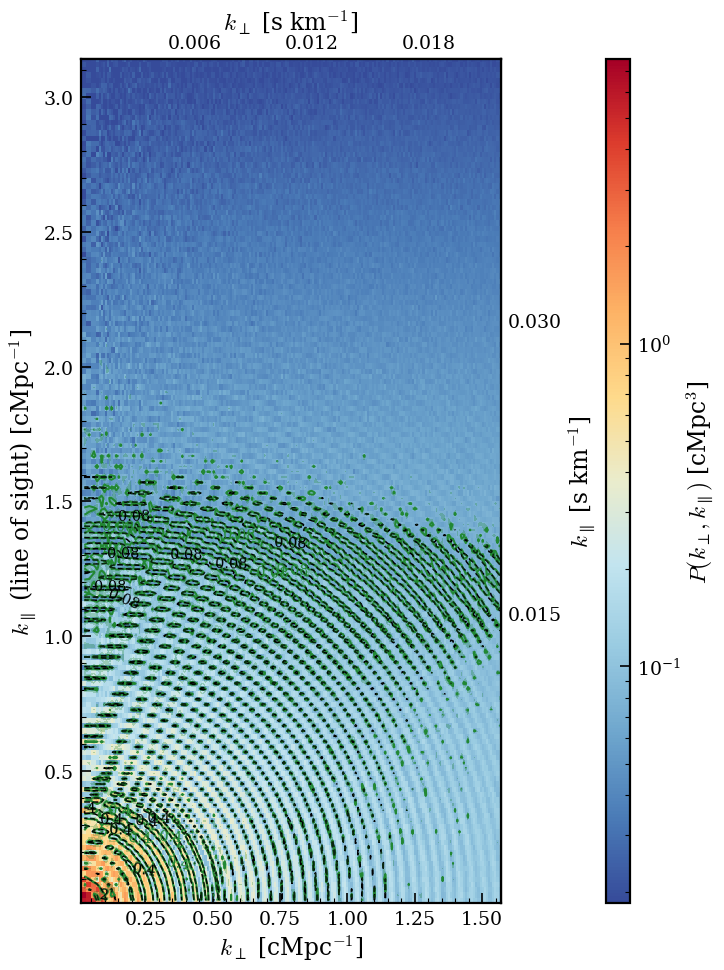

k map: 2560 rows, k_par = 2 pi m / L up to pi n_los / L = 50.265 cMpc^-1, shown up to pi u / dv = 3.142 cMpc^-1 (the overflux map); chi2/dof per bin against the expectation (every row) 7726684.50


In [12]:
densE = dict(dB["total"], axes=axB)
fig, ax, chi2_B = plot_overflux_kpar_kperp(
      densE, kms_per_cMpc=u, kperp_edges=K_EDGES_B, n_sigma=1, unit="cMpc", theory=thB, kpar_max=np.pi * N_PIX / L_BOX,
) # drawn: k_par <= pi u / dv, the range of the overflux map (D2)
plt.show()
print(f"k map: {axB['kpar_edges'].size - 1} rows, k_par = 2 pi m / L up to pi n_los / L = {np.pi * n_los / L_BOX:.3f} cMpc^-1, "
      f"shown up to pi u / dv = {np.pi * N_PIX / L_BOX:.3f} cMpc^-1 (the overflux map); chi2/dof per bin against the expectation (every row) {chi2_B:.2f}")

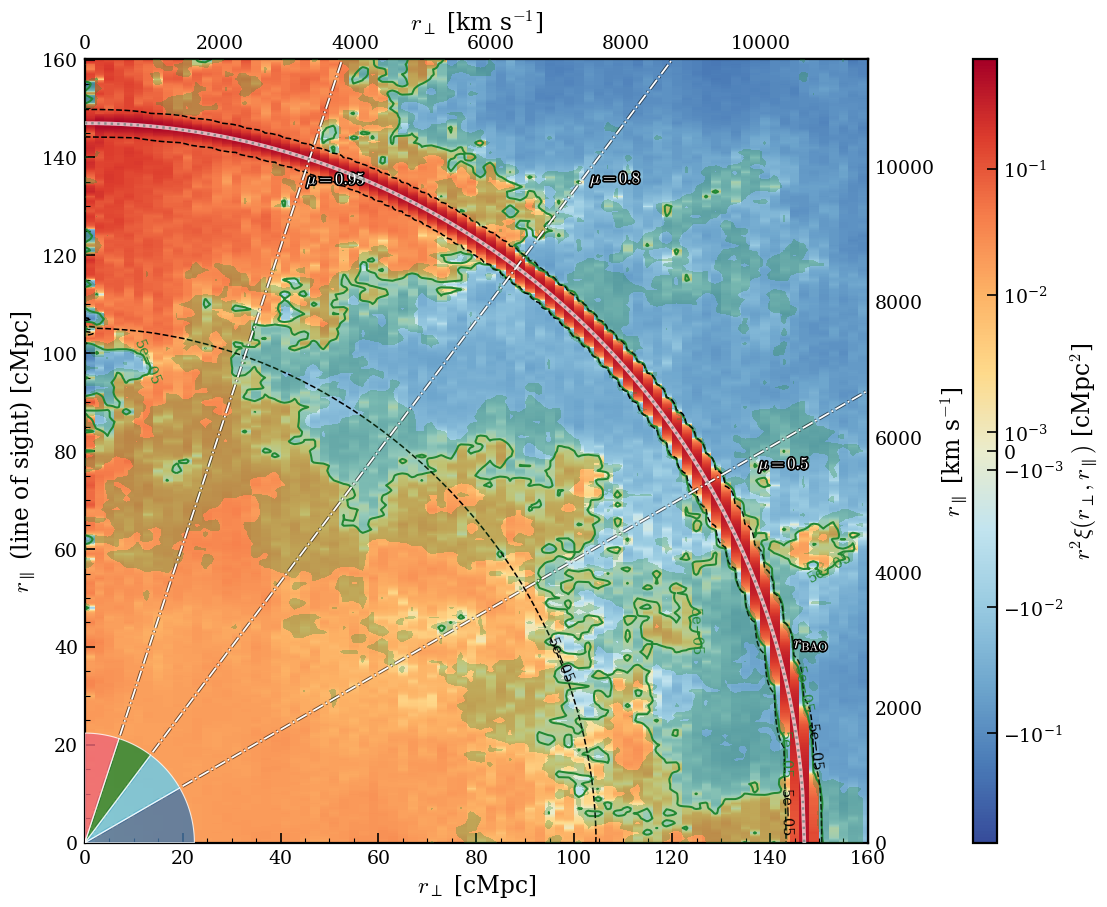

map: 2561 rows, one per separation j dx / p from 0 to L / 2


In [13]:
fig, ax, curves_B = plot_overflux_rpar_rperp(
    densE, kms_per_cMpc=u, rperp_edges=RPERP_EDGES_B, r_bao=boxes.r_bao, n_sigma=1,
    color_scale="symlog", quantity="r2xi", unit="cMpc", theory=thB, levels=[5*10**-5]
    )
plt.show()
print(f"map: {axB['rpar_edges'].size - 1} rows, one per separation j dx / p from 0 to L / 2")

**The integral constraint.** The density has an analytic model: as in 08 (A3), the continuous $\xi(r)$ minus the mean
of $\xi$ over the box, $\bar\xi_V$ (`integral_constraint`), against the expectation on this lattice.


In [14]:
from skewerjax.summary_stats import integral_constraint
GRF = boxes.grf()
xi_cont = lambda r: np.asarray(GRF.correlation(r), dtype=float)                    # the closed form of the toy model
XI_BAR = integral_constraint(xi_cont, L_BOX)
r_b = axB["r_iso"]
ok_b = np.isfinite(thB["xi_iso"]) & (r_b > 0)
dev_b = np.abs(xi_cont(r_b[ok_b]) - XI_BAR - thB["xi_iso"][ok_b])
print(f"xi_bar_V = {XI_BAR:.4e}; max |(xi - xi_bar_V) - expectation on the lattice|: r < L / 4 {dev_b[r_b[ok_b] < L / 4].max():.2e}, r < L / 2 {dev_b.max():.2e}; "
      f"r >= 6 dx and r < L / 4 {dev_b[(r_b[ok_b] >= 6 * dx) & (r_b[ok_b] < L / 4)].max():.2e}, r >= 6 dx and r < L / 2 {dev_b[r_b[ok_b] >= 6 * dx].max():.2e}")

xi_bar_V = 2.7375e-06; max |(xi - xi_bar_V) - expectation on the lattice|: r < L / 4 3.77e-03, r < L / 2 3.77e-03; r >= 6 dx and r < L / 4 2.29e-06, r >= 6 dx and r < L / 2 4.01e-06


## Part C — Transmission and overflux

**Transmission and overflux.** $T = e^{-\tau}$ is the **transmission**; the flux is the observed $F = F_0\,T$, the
continuum $F_0$ times the transmission. The overflux follows continuum-fitting convention:

$$
\delta = \frac{F}{F_0\,\bar T} - 1 = \frac{T}{\bar T} - 1,\qquad \bar T = \langle T\rangle,
$$

the mean over a set of pixels chosen by `MEAN`. Each line $j$ has $\delta_j = T_j/\bar T_j - 1$, and the
total, $T = \prod_j T_j$, has $\bar T = \langle\prod_j T_j\rangle \neq \prod_j \bar T_j$.

**The normalisation modes.** $\langle\delta\rangle = 0$ holds over the set of pixels of the mean:

| `mean` | $\bar T$ over | removes | use it for |
|---|---|---|---|
| `"redshift"` (default) | the pixels at the same redshift, of every skewer of every box: $\bar T(z)$ | the mean-flux evolution along the skewers, a pattern shared by all of them | the observational convention, the mean flux as a function of $z$ |
| `"global"` | every pixel of every skewer of every box: one number | only the overall mean; a drift of $\bar T$ along $v$ stays in $\delta$ | a path without evolution |
| `"box"` | every pixel of every skewer of one box | the box-to-box scatter of the mean ($\mathbf k = 0$ of each box) | normalising each realisation by itself |
| `"skewer"` | the pixels of one skewer | the $k_\parallel = 0$ mode of every skewer | mimicking a fitted continuum amplitude |

All skewers share one grid of pixel scale factors here, so $\bar T(z)$ is the mean at each pixel over the ensemble.
**Here `MEAN = "redshift"`**.

**The continuum.** Here $F_0$ is known (in effect $F/F_0 = T$), so $\delta = T/\bar T - 1$ exactly. In data, $F_0$
must be estimated for each quasar. A per-quasar change in the continuum's amplitude or slope is indistinguishable from
a large-scale fluctuation of the transmission along that sightline, so even a correct continuum model absorbs those
modes of $\delta$; analyses correct for this with a projection. It does not arise here, because $F_0$ is known.

In [15]:
from skewerjax.summary_stats import ensemble_mean_transmissions, overflux_check
MEAN = "redshift"                                                               # T_bar(z): the table of the modes above
T = np.exp(-TAU)                                                                # the transmission of each line (n_box, N_lines, N_sk, N_PIX)
T_BAR = ensemble_mean_transmissions(T, mean=MEAN, grid=A_PIX)                   # T_bar of every line and of the total: (n_box, N_lines + 1, N_sk, N_PIX), a view
DELTA = np.concatenate([T, T.prod(axis=1, keepdims=True)], axis=1) / T_BAR - 1  # delta = T / T_bar - 1 (every line, total)
CHECK = overflux_check(DELTA, T_BAR, mean=MEAN)                                 # <delta> = 0 over the sets of MEAN, C, the decomposition
T_v = ensemble_mean_transmissions(T, mean="redshift")[0, :, 0]                  # T_bar(v) at each pixel over the ensemble, whatever MEAN (N_lines + 1, N_PIX)
drift = T_v / T_v.mean(axis=1, keepdims=True) - 1                               # the drift along v of each line and the total
print("mean transmission over every pixel: " + ", ".join(f"{nm} {t.mean():.4f}" for nm, t in zip([*NAMES_L, "total"], T_v)) + f". scale factor from {A_PIX[0]:.5f} to {A_PIX[-1]:.5f}")
print("drift of T_bar(v) along v, T_bar(v) / <T_bar> - 1 (diagnostic): " + ", ".join(
      f"{n} {d[:5].mean():+.4f} -> {d[-5:].mean():+.4f} (rms {d.std():.1e})" for n, d in zip([*NAMES_L, "total"], drift))
      + f"; Delta ln a = v_per / c = {PERIOD / phys.c_kms:.4f}")
print(f"normalisation: max |<delta>| over the sets of MEAN = {CHECK['mean_delta_level'].max():.1e} (every line, the "
      f"total); C = T_bar / prod_j T_bar_j - 1 = {CHECK['C']:.4e} (mean), |C - sum_(|A| >= 2) <delta_A>| = {CHECK['C_error']:.1e}; "
      f"max |[sum_A delta_A - C] / (1 + C) - delta_tot| = {CHECK['decomposition_error']:.1e}")
del T

mean transmission over every pixel: Lyα 0.8143, Si III 0.9232, total 0.7518. scale factor from 0.33329 to 0.30858
drift of T_bar(v) along v, T_bar(v) / <T_bar> - 1 (diagnostic): Lyα +0.0000 -> -0.0001 (rms 9.6e-04), Si III -0.0002 -> -0.0003 (rms 2.5e-04), total -0.0002 -> -0.0004 (rms 1.0e-03); Delta ln a = v_per / c = 0.0773
normalisation: max |<delta>| over the sets of MEAN = 3.6e-10 (every line, the total); C = T_bar / prod_j T_bar_j - 1 = -1.0202e-06 (mean), |C - sum_(|A| >= 2) <delta_A>| = 9.7e-15; max |[sum_A delta_A - C] / (1 + C) - delta_tot| = 4.0e-08


### C1 · One skewer, from the gas to the flux contrast

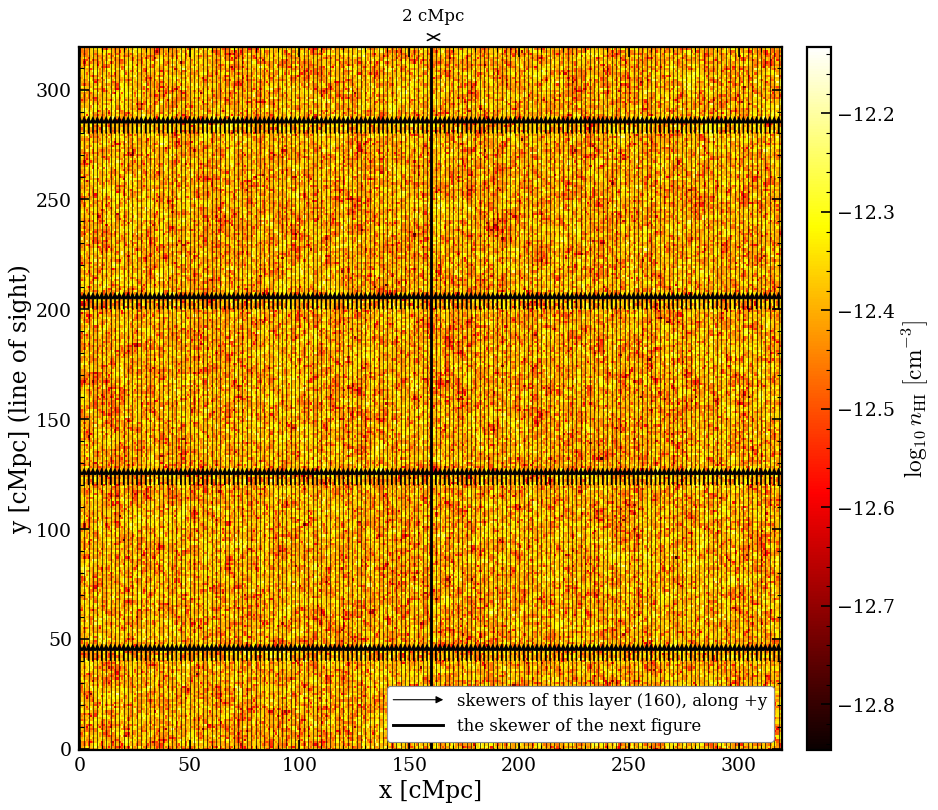

160 skewers in the layer i_z = 0, 2 cMpc apart; the skewer of the next figure: x = 160.0 cMpc


In [16]:
from skewerjax.utils.plotting import plot_skewer_slice, plot_toy_skewer
on_z0 = np.flatnonzero(COLS[:, 1] == 0)
j = int(on_z0[np.argmin(np.abs(COLS[on_z0, 0] - boxes.n_cells // 2))])   # the column nearest to x = L/2 with i_z = 0
ix, iz = COLS[j]
fig, ax, sl_info = plot_skewer_slice(fields0, L_BOX, COLS, z_index=0, highlight=(ix, iz), cmap="hot")
plt.show()
print(f"{sl_info['n_row']} skewers in the layer i_z = 0, {sl_info['spacing_cMpc']:.4g} cMpc apart; the skewer of the next figure: "
      f"x = {ix * boxes.dx:.1f} cMpc")

**Along the skewer.** Rows (a) and (b) are along the comoving position $y$ (the $N$ cell values, as steps); rows (c)
to (e) along the velocity of the $\mathrm{Ly}\alpha$ axis, on which every other line $j$ is evaluated at $v + \Delta v_j$ and wrapped
into the period. The overdensities (b) of H I, Si III and Si II are identical by construction (one gas, with one temperature);
their absorption is not: the metal lines are narrower ($b \propto m^{-1/2}$) and displaced by the separations $\Delta v_{\mathrm{Ly}\alpha\text{–}j}$ of the
lines, wrapped into the period (printed below). Row (c) is the transmission $T = e^{-\tau}$ of each line and the total
$T = \prod_j T_j$; row (d) the mean transmission $\bar T$ that normalises this skewer, from the step (c) of Part C
(`MEAN`: $\bar T(z)$ of the ensemble with `"redshift"`; that skewer's or box's value with `"skewer"` or `"box"`); row (e)
their overfluxes, $\delta = T/\bar T - 1$, so the mean of (e) along this one skewer need not vanish. The very thin grey
vertical lines are the grids: in (a) and (b) the points of the path ($p$ per cell), in (c) to (e) the pixel centres,
where $\tau$ is evaluated. When
the lines of a panel would be too dense to read, they are drawn only in a zoomed inset, whose range is marked on the
panel.

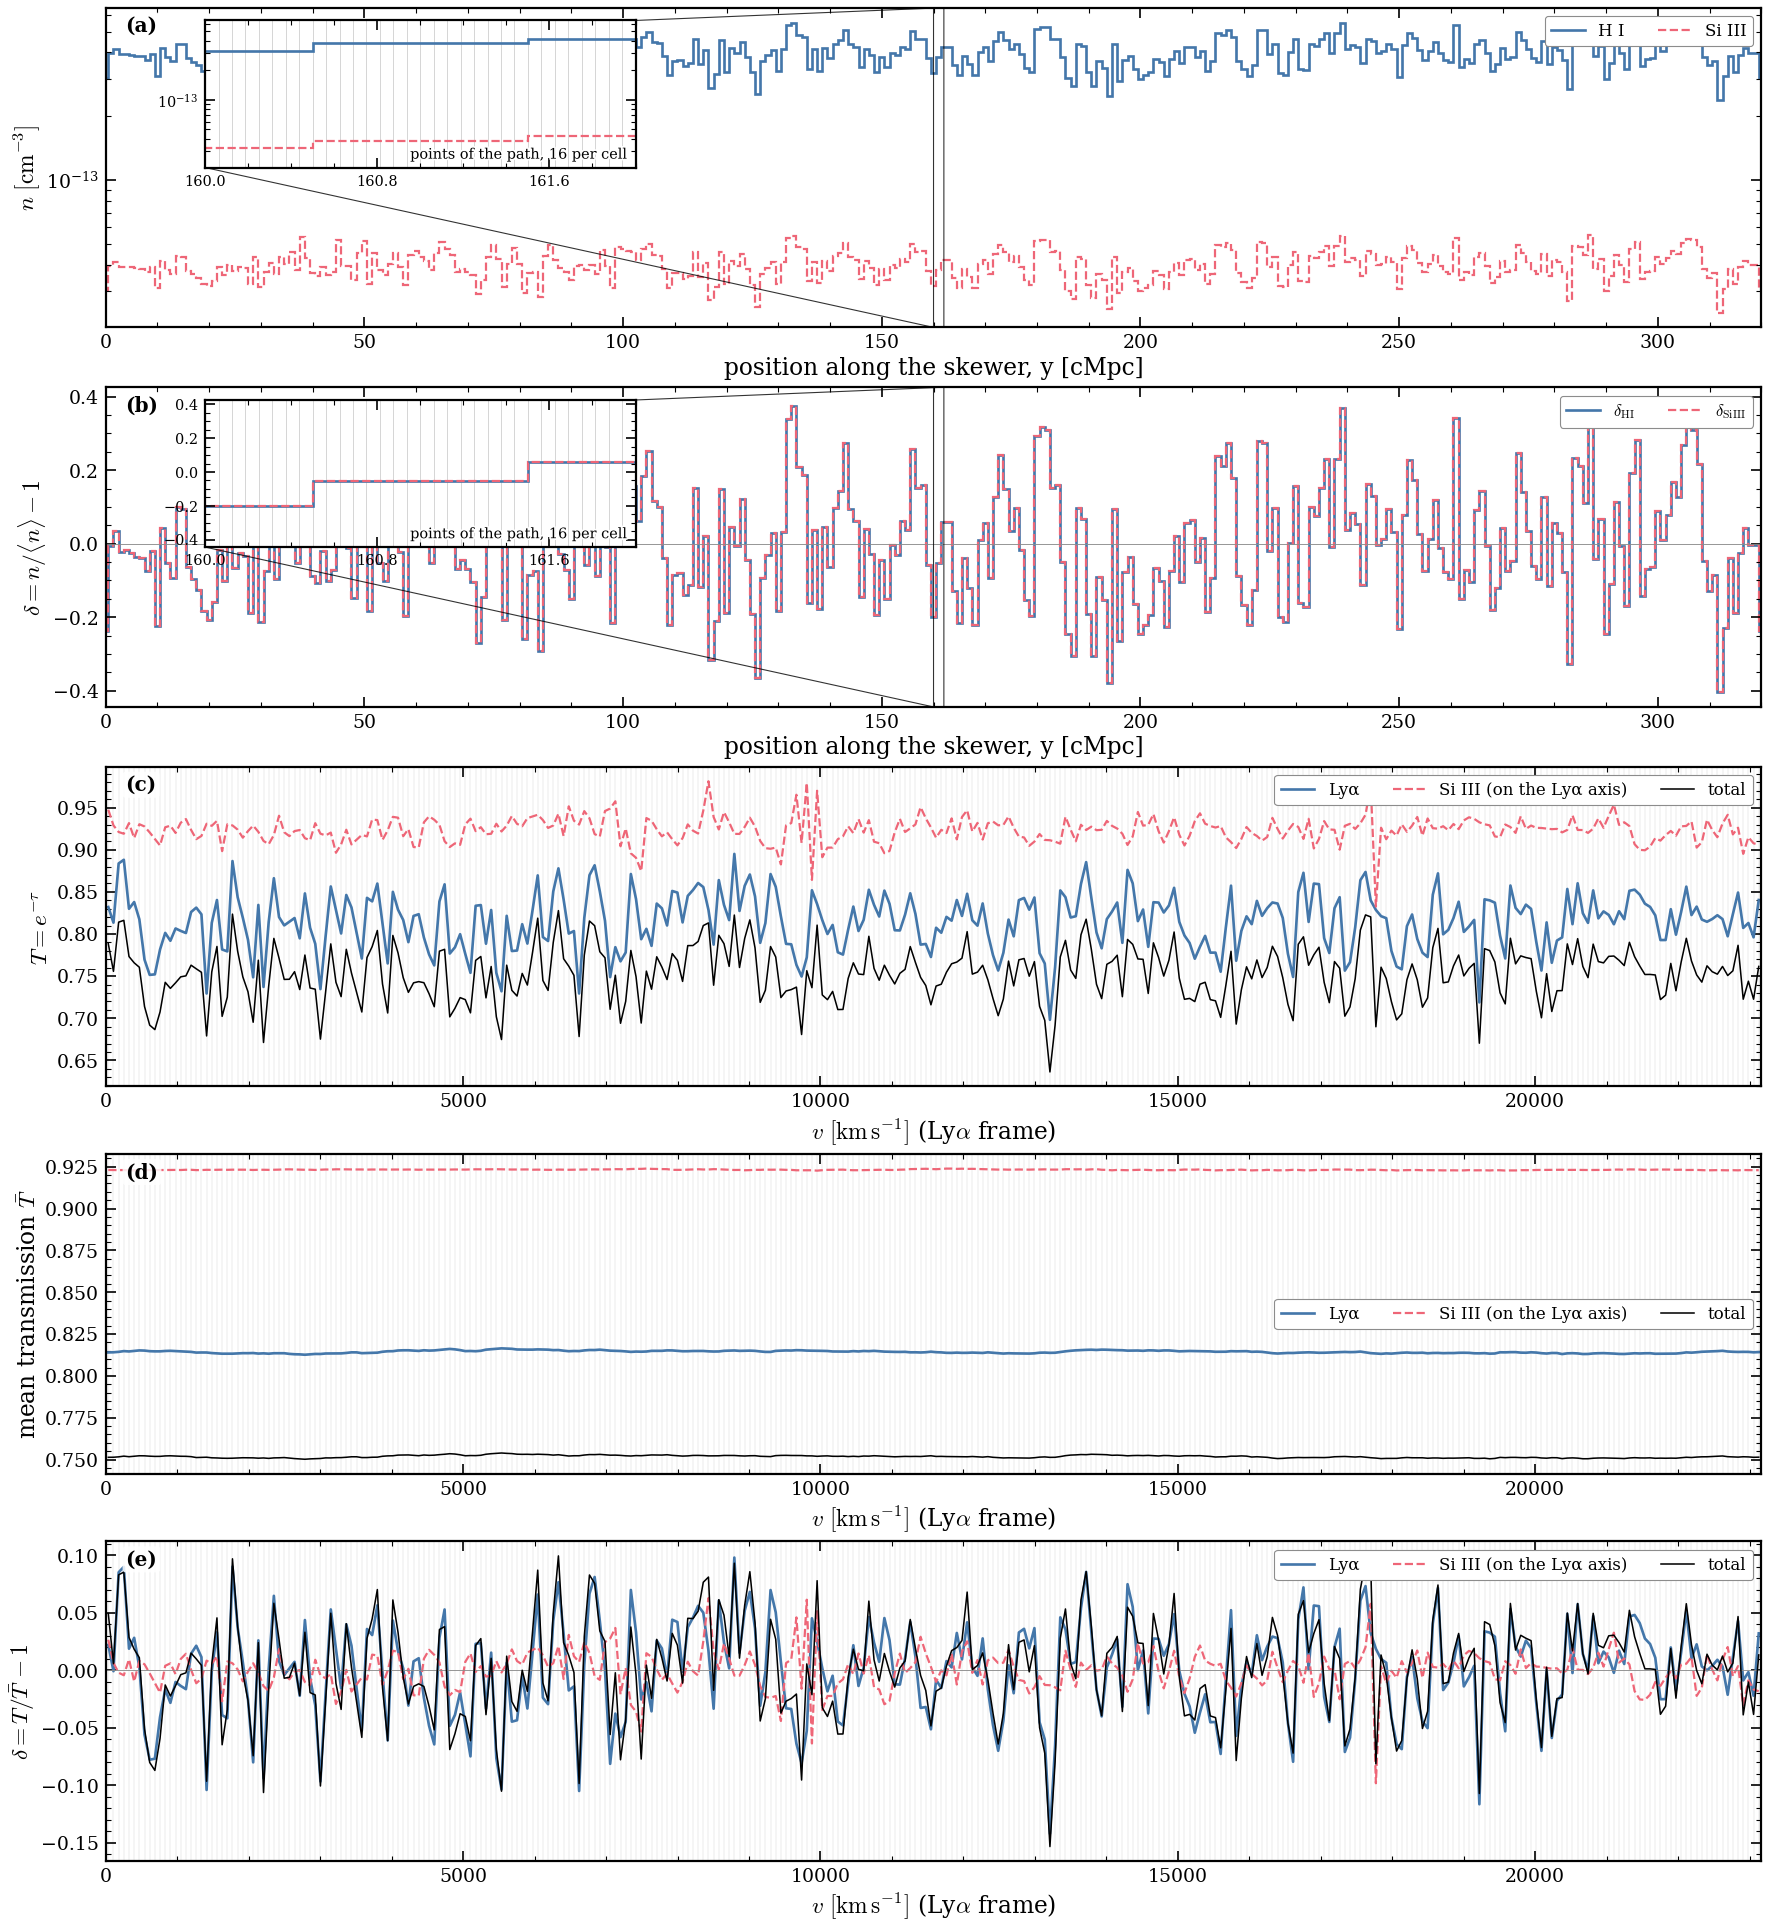

line separations Delta v [km/s], folded into [0, v_per / 2] with v_per = 23164 km/s [km/s and cMpc]: Lyα–Si III 2270 -> 2270 = 31.4; b(Lya) / b(Si) = 5.28


In [17]:
from skewerjax.utils.plotting import line_pairs
n_col = {sp: fields0["n"][sp][ix, :, iz] for sp in boxes.species}
fig, axs, grid_info = plot_toy_skewer(L_BOX, n_col, V, TAU[0][:, j], mean_transmission=T_BAR[0][:, j], points_per_cell=POINTS_PER_CELL, line_ids=LINE_IDS)
add_panel_letters(axs)
plt.show()
PAIRS = line_pairs(LINE_IDS, np.asarray(LINES.delta_v), PERIOD)           # every pair of lines, its separation folded into [0, v_per / 2]
dv_12 = float(LINES.delta_v[1])
dv_fold = PAIRS[0]["fold"]                                                # Si III - Lya, folded into half the period
print(f"line separations Delta v [km/s], folded into [0, v_per / 2] with v_per = {PERIOD:.0f} km/s [km/s and cMpc]: " + "; ".join(
      f"{NAMES_L[p['i']]}–{NAMES_L[p['j']]} {p['dv']:.0f} -> {p['fold']:.0f} = {p['fold'] / u:.1f}" for p in PAIRS)
      + f"; b(Lya) / b(Si) = {b_T0[LINE_IDS[0]] / b_T0[LINE_IDS[1]]:.2f}")

## Part D — Summary statistics of the overfluxes

**Two kinds of axis.** Along the line of sight the coordinate is a **velocity**, $v$ [km/s]; across it, the coordinates
are comoving **distances**, $x_\perp$ [cMpc]. One approximate factor relates them, the mean Hubble rate along a skewer
($dv/dy = aH$ changes along it with $a(y)$):

$$
\Delta v \simeq u\,\Delta x,\qquad u = \frac{1}{L}\int_0^L aH\,dy = \frac{v_{\rm per}}{L}.
$$

Two rules follow:

- **Maps** ($r_\parallel$ against $r_\perp$): each axis keeps its native coordinate. The bottom axis is the
  perpendicular one, in cMpc; the left axis is the line of sight, in km/s.
  For reference only, a top axis gives the perpendicular
  coordinate in km/s and a right axis the line of sight in cMpc, both through $u$.
- **Isotropic quantities that combine both axes** ($\lvert\mathbf r\rvert$, $\lvert\mathbf k\rvert$, $\mu$, $P$, etc.):
  the line of sight is converted to comoving distance, $r_\parallel = v/u$ and $k_\parallel = u\,k_v$, and they are
  reported in comoving units: $r$ in cMpc, $r^2\xi$ in $\mathrm{cMpc}^2$, $k$ in $\mathrm{cMpc}^{-1}$ (the top axes give km/s and s/km for
  reference). On the lattice a pixel $dv$ spans $dv/u = L/N_{\rm pix}$ cMpc, so the lattice is a cube of side $L$.

**What the lattice resolves.** The statistics are computed on exactly the lattice of the skewers, with no regridding.
Along the LoS: from the pixel size $dv$ up to the span of the box, $v_{\rm per}$. Across it:
from the skewer spacing $s\,dx$ (set by `stride`) up to $L$.

**Errors.** Points with error bars are the mean over the boxes and its error.


### D1 · The bins and the statistics

**The statistics, from arrays and geometry only.** P1D and $\xi_{\rm 1D}$ by one 1D FFT per skewer
(`skewer_p1d`, `skewer_xi1d`), the 3D statistics on the lattice of the skewers with the bins `EDGES_C` (`lattice_grid`,
`measure_lattice`), and, in Part B, the density on the same skewers (`skewer_density_statistics`, `lattice_density_theory`): no
box class enters, only $\delta$, $dv$, the lattice spacing and the bins.

**The bins of the overfluxes** (next cell), passed to the 3D statistics (`lattice_grid`) and to the figures of D2 and D3. The statistics use exactly
the lattice the skewers produce, with no regridding or interpolation before the FFT: $s\,dx$ across, $dv$ along the line
of sight (printed above), converted to comoving units with the one factor $u$ for the isotropic quantities (above).

- $r_\perp$, `RPERP_EDGES_C`: width the skewer spacing $s\,dx$, from 0 to $L/2$; the first bin holds the pairs on the same
  skewer.
- $r_\parallel$: the lattice's own separations, one row per pixel separation, $r_\parallel = j\,dv$ from 0 to
  $v_{\rm per}/2$, each row centred on its separation (no array: they follow from $N_{\rm pix}$).
- $\lvert\mathbf r\rvert$, `R_EDGES_C`, also the $\lvert\mathbf r\rvert$ bins of the wedges: width the coarser lattice
  spacing in cMpc, $\max(s\,dx, dv/u)$, from 0 to $L/2$.
- $\lvert\mathbf k\rvert$, `K_EDGES_C`: the binning of `K_EDGES` up to the smaller of the two Nyquist frequencies in
  $\mathrm{cMpc}^{-1}$, $\pi/(s\,dx)$ and $\pi u/dv$, so that every bin holds all directions.

In [18]:
# The bins of the 3D statistics of the overfluxes (D1) in comoving units [cMpc], [cMpc^-1] (the line of sight converted with u)
d_min, d_max, dv_c = D_PERP.min(), D_PERP.max(), DV / u                           # the skewer spacing s dx, a pixel dv / u [cMpc]
RPERP_EDGES_C = np.arange(0, L / 2 + d_min, d_min)                                # r_perp: width s dx to L / 2 (first bin: the same skewer)
R_EDGES_C = np.arange(0, L / 2 + max(d_max, dv_c), max(d_max, dv_c))              # |r| (and the wedges): the coarser spacing, to L / 2
K_EDGES_C = bao_k_edges(2 * np.pi / L, min(np.pi / d_max, np.pi / dv_c), 3.0 / boxes.sigma_bao, k_1=None, dk_factor=0.4)                 # |k|: as K_EDGES, to the smaller Nyquist frequency
EDGES_C = dict(k_edges=K_EDGES_C, r_edges=R_EDGES_C, rperp_edges=RPERP_EDGES_C)
print(f"overflux bins: r_perp {RPERP_EDGES_C.size - 1} of width {d_min:.4g} cMpc up to {RPERP_EDGES_C[-1]:.1f} cMpc; r_par one row per "
      f"pixel separation, {N_PIX // 2 + 1} rows from 0 to v_per / 2; |r| {R_EDGES_C.size - 1} of width {max(d_max, dv_c):.4g} cMpc "
      f"up to {R_EDGES_C[-1]:.1f} cMpc; |k| {K_EDGES_C.size - 1} up to {K_EDGES_C[-1]:.4f} cMpc^-1")
print(f"full coverage of the lattice: |k| <= min(pi / (s dx), pi u / dv) = min({np.pi / d_max:.4f}, {np.pi / dv_c:.4f}) cMpc^-1, |r| <= L / 2 = {L / 2:.1f} cMpc")

overflux bins: r_perp 80 of width 2 cMpc up to 160.0 cMpc; r_par one row per pixel separation, 161 rows from 0 to v_per / 2; |r| 80 of width 2 cMpc up to 160.0 cMpc; |k| 194 up to 1.5708 cMpc^-1
full coverage of the lattice: |k| <= min(pi / (s dx), pi u / dv) = min(1.5708, 3.1416) cMpc^-1, |r| <= L / 2 = 160.0 cMpc


In [19]:
from skewerjax.summary_stats import ensemble_mean, lattice_grid, measure_lattice, skewer_p1d, skewer_xi1d
from skewerjax.summary_stats import GRID_KEYS
OVERFLUX_FIELDS = (*LINE_IDS, "total")                         # the overflux of each line and of the total
GRID_C = lattice_grid(n_x, n_z, N_PIX, L_BOX, D_PERP, **EDGES_C, log=print)   # the 3D statistics on the lattice, bins EDGES_C
P1D_EACH, XI1D_EACH, F3D_EACH = [], [], []
for i in range(n_box):                                           # every statistic per box, from arrays and geometry only
    K1D, p = skewer_p1d(DELTA[i], DV)                            # P1D (N_lines + 1, N_PIX / 2 + 1): one 1D FFT per skewer [km/s]
    LAGS, x = skewer_xi1d(DELTA[i], DV)                          # xi1D (N_lines + 1, N_PIX / 2 + 1) at every lag j dv
    P1D_EACH.append(dict(p1d=p))
    XI1D_EACH.append(dict(xi1d=x))
    # skewer samples: on the skewers' own lattice, along the line of sight N_PIX pixels, across it the skewer spacing; no deposition, window or interlacing
    F3D_EACH.append({f: measure_lattice(DELTA[i, j], GRID_C) for j, f in enumerate(OVERFLUX_FIELDS)})  # P, xi in 3D
P1D = dict(ensemble_mean(P1D_EACH, ("p1d",)), k=K1D)             # the mean over the boxes and its error, k [s/km]
XI1D = dict(ensemble_mean(XI1D_EACH, ("xi1d",)), lags=LAGS)
FLUX3D = {f: ensemble_mean([r[f] for r in F3D_EACH], GRID_KEYS) for f in OVERFLUX_FIELDS}
AXES3D = GRID_C.axes()                                           # the bins of D1 [cMpc], [cMpc^-1]
print(f"statistics of {n_box} boxes: P1D and xi1D of {len(OVERFLUX_FIELDS)} overfluxes along {n_sk} skewers each, the 3D "
      f"statistics on the lattice {GRID_C.shape} (overflux) and {GRID_B.shape} (density)")

statistics of 2 boxes: P1D and xi1D of 3 overfluxes along 25600 skewers each, the 3D statistics on the lattice (160, 320, 160) (overflux) and (160, 5120, 160) (density)


### D2 · The $(k_\perp, k_\parallel)$ & $(r_\perp, r_\parallel)$ planes

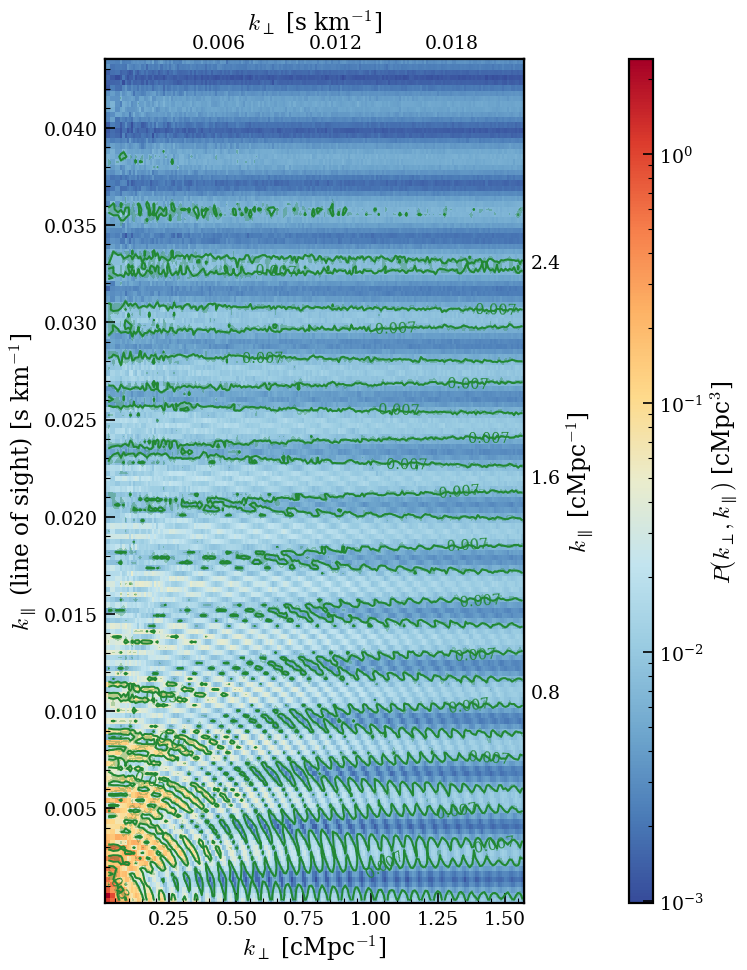

k map: 160 rows, k_par = 2 pi m / v_per from 2.71e-04 to pi / dv = 4.34e-02 s/km; 194 columns of k_perp (K_EDGES_C), of which 0 hold no mode


In [20]:
from skewerjax.utils.plotting import (fold_periodic, plot_overflux_3d, plot_overflux_kpar_kperp,
                                      plot_overflux_rpar_rperp, los_scales)
ax3, f3 = AXES3D, FLUX3D                                                 # comoving bins [cMpc], [cMpc^-1]
from skewerjax.utils.plotting import field_names
NAMES = field_names(OVERFLUX_FIELDS)                                     # Lyα, Si III, Si II 1193, Si II 1190, total
tot = dict(f3["total"], axes=ax3)                                        # the total overflux and its bins
fig, ax, _ = plot_overflux_kpar_kperp(tot, kms_per_cMpc=u, kperp_edges=K_EDGES_C, n_sigma=1)
plt.show()
print(f"k map: {ax3['kpar_edges'].size - 1} rows, k_par = 2 pi m / v_per from {2 * np.pi / PERIOD:.2e} to pi / dv = "
      f"{np.pi / DV:.2e} s/km; {ax3['kperp_edges'].size - 1} columns of k_perp (K_EDGES_C), of which "
      f"{int(np.sum(ax3['n_modes_P_map'].sum(0) == 0))} hold no mode")

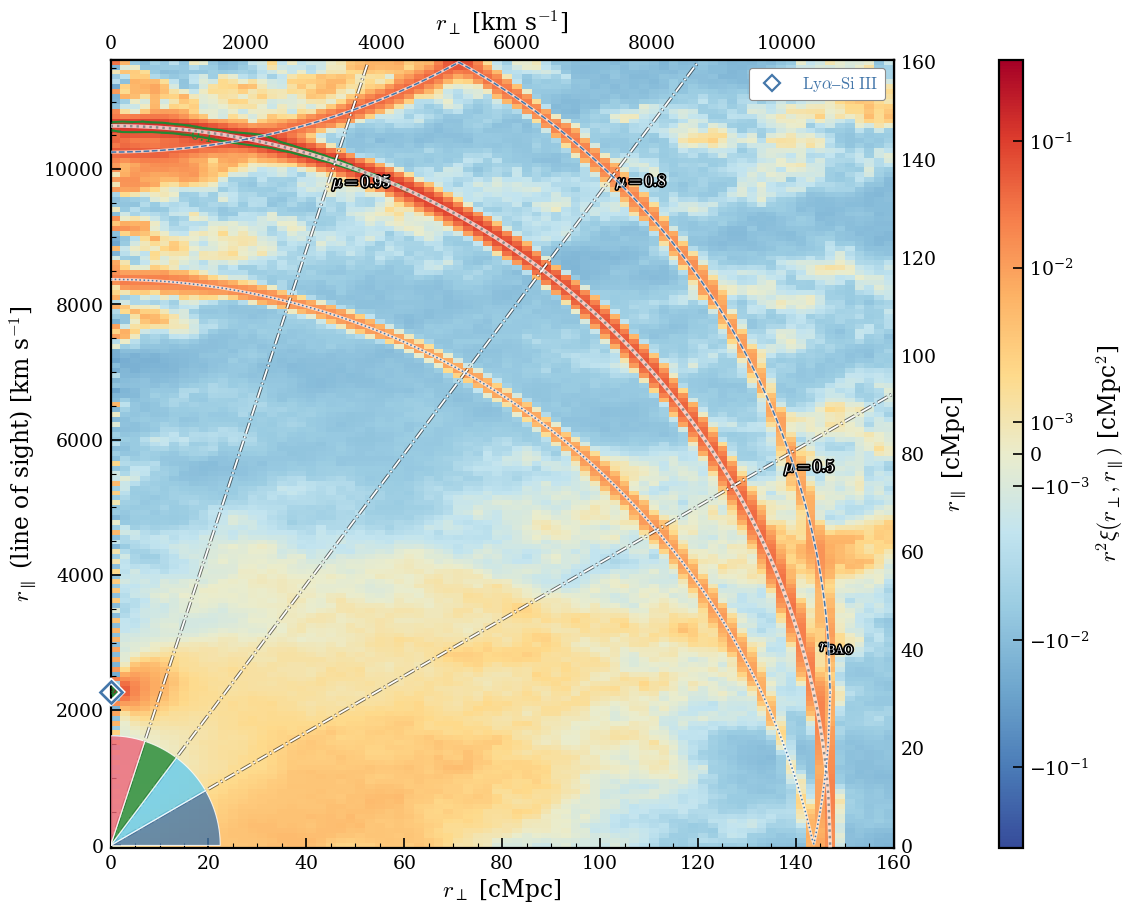

map: 161 rows, one per pixel separation j dv (dv = 72.39 km/s), from 0 to 11582 km/s = v_per / 2; 80 columns of r_perp of width 2 cMpc up to 160.0 cMpc; u r_BAO = 10641 km/s
Delta = Delta v / u = 31.36 cMpc (2270 km/s); the echo branches start on the line of sight at |r_BAO - Delta| = 115.6 and r_BAO + Delta = 141.6 cMpc (folded into [0, L / 2]) and meet at (r_perp, r_par) = (147, 31.4) cMpc
Si III - Lya at r_par = Delta, r_perp bin 0 (0.0-2.0 cMpc): xi = 3.40e-04, excess over the rows two pixels away 3.32e-04 = 66.0 sigma
Si III - Lya at r_par = Delta, r_perp bin 1 (2.0-4.0 cMpc): xi = 4.99e-05, excess over the rows two pixels away 2.81e-05 = 113.1 sigma
  mean r^2 xi along the r_BAO curve: +0.064 +- 0.000 cMpc^2
  mean r^2 xi along the echo +Delta v (Si III - Lya) curve: +0.025 +- 0.000 cMpc^2
  mean r^2 xi along the echo -Delta v (Si III - Lya) curve: +0.010 +- 0.000 cMpc^2
b_S / b_L = sqrt(P_SiIII / P_Lya) at the lowest |k| = 0.327: the expected amplitude of the echoes relative to 

In [21]:
fig, ax, curves = plot_overflux_rpar_rperp(
      tot, kms_per_cMpc=u, rperp_edges=RPERP_EDGES_C, r_bao=boxes.r_bao, delta_v=np.asarray(LINES.delta_v),
      line_ids=LINE_IDS, pairs="all", n_sigma=1, color_scale="symlog", quantity="r2xi"
)  # every pair, metal-metal included, in its colour: diamond, echo + dashed, echo - dotted; the ring grey dotted
plt.show()
r_par_max = ax3["rpar"][-1]                                              # the last row: half the period [cMpc]
print(f"map: {ax3['rpar_edges'].size - 1} rows, one per pixel separation j dv (dv = {u * np.diff(ax3['rpar_edges'])[0]:.2f} km/s), "
      f"from 0 to {u * r_par_max:.0f} km/s = v_per / 2; {ax3['rperp_edges'].size - 1} columns of r_perp of width "
      f"{np.diff(ax3['rperp_edges'])[0]:.3g} cMpc up to {ax3['rperp_edges'][-1]:.1f} cMpc; u r_BAO = {u * boxes.r_bao:.0f} km/s")
DELTA = dv_fold / u                                                      # the line separation in comoving units [cMpc]
ends = fold_periodic([boxes.r_bao - DELTA, boxes.r_bao + DELTA], L_BOX)
print(f"Delta = Delta v / u = {DELTA:.2f} cMpc ({dv_fold:.0f} km/s); the echo branches start on the line of sight at "
      f"|r_BAO - Delta| = {ends[0]:.1f} and r_BAO + Delta = {ends[1]:.1f} cMpc (folded into [0, L / 2]) and meet at "
      f"(r_perp, r_par) = ({boxes.r_bao:g}, {DELTA:.1f}) cMpc")
X, Xe = f3["total"]["xi_map"], f3["total"]["xi_map_err"]
ip = int(np.argmin(np.abs(ax3["rpar"] - DELTA)))                         # the r_par row of Delta
for q in (0, 1):                                    # r_perp columns: 0 = pairs on the same skewer, 1 = one transverse spacing
    excess = X[ip, q] - 0.5 * (X[ip - 2, q] + X[ip + 2, q])
    print(f"Si III - Lya at r_par = Delta, r_perp bin {q} ({ax3['rperp_edges'][q]:.1f}-{ax3['rperp_edges'][q + 1]:.1f} cMpc): "
          f"xi = {X[ip, q]:.2e}, excess over the rows two pixels away {excess:.2e} = {excess / Xe[ip, q]:.1f} sigma")
b_ratio = np.sqrt(f3["SiIII-1206"]["P_iso"][0] / f3["HI-LyA"]["P_iso"][0])  # b_S / b_L from the spectra at the lowest |k|
R2 = np.nan_to_num(ax3["rpar_map"]) ** 2 + np.nan_to_num(ax3["rperp_map"]) ** 2
M, Me = R2 * X, R2 * Xe                                                  # r^2 xi of the map and its error [cMpc^2]

def along(c):                                       # the mean of r^2 xi over the cells a curve crosses, and its error
    i = np.clip(np.searchsorted(ax3["rpar_edges"], np.asarray(c["r_par"]) / u) - 1, 0, M.shape[0] - 1)
    k = np.clip(np.searchsorted(ax3["rperp_edges"], np.asarray(c["r_perp"])) - 1, 0, M.shape[1] - 1)
    cells = np.unique(np.stack([i, k]), axis=1)
    return M[cells[0], cells[1]].mean(), np.sqrt(np.sum(Me[cells[0], cells[1]] ** 2)) / cells.shape[1]

for name, label in (("ring", "r_BAO"), ("echo +", "echo +Delta v (Si III - Lya)"), ("echo -", "echo -Delta v (Si III - Lya)")):
    m, e = along(curves[name])
    print(f"  mean r^2 xi along the {label} curve: {m:+.3f} +- {e:.3f} cMpc^2")
print(f"b_S / b_L = sqrt(P_SiIII / P_Lya) at the lowest |k| = {b_ratio:.3f}: the expected amplitude of the echoes relative to "
      f"the ring")
shared = CHECK["mean_delta"][-1]                                         # <delta_tot> at each pixel, over every skewer of every box
s_glob = drift[-1] / (1 + drift[-1].mean())                              # the pattern a global mean would keep: T_bar(v) / <T_bar> - 1
print(f"pattern shared by every skewer in delta_tot (MEAN = {MEAN!r}, a diagnostic): rms {shared.std():.1e} "
      f"(zero by construction with 'redshift'); with mean='global' it would be the drift of T_bar(v), rms {s_glob.std():.1e}, "
      f"adding about {s_glob.var():.1e} to xi at every r_perp (the k_perp = 0 modes)")

**The echoes of the BAO ring.** On large scales the overflux of each line follows the gas, $\delta_j \simeq b_j\delta_g$,
with a bias $b_j$. Si III is evaluated on the $\mathrm{Ly}\alpha$ axis at $v + \Delta v_{\mathrm{Ly}\alpha\text{–Si III}}$, so it samples the gas a
distance $\Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u$ further along the line of sight:

$$
\delta_{\rm tot}(\mathbf x) \simeq b_L\,\delta_g(\mathbf x) + b_S\,\delta_g\big(\mathbf x + (\Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u)\,\hat{\mathbf y}\big).
$$

Its correlation, with $\xi_g$ that of the gas:

$$
\xi_{\rm tot}(r_\perp, r_\parallel) \simeq \big(b_L^2 + b_S^2\big)\,\xi_g\Big(\sqrt{r_\perp^2 + r_\parallel^2}\Big)
+ b_Lb_S\Big[\xi_g\Big(\sqrt{r_\perp^2 + (r_\parallel - \Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u)^2}\Big) + \xi_g\Big(\sqrt{r_\perp^2 + (r_\parallel + \Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u)^2}\Big)\Big].
$$

The cross terms copy the gas correlation shifted by $\pm\Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u$ along the line of sight: its peak at $r = 0$ becomes the
spot at $(0, \Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u)$ (the diamond), and its BAO ring two rings centred on $(0, \pm\Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u)$. After folding
$r_\parallel \to \lvert r_\parallel\rvert$, both lie on the BAO ring re-centred on the Si III spot:

$$
r_\perp^2 + (r_\parallel - \Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u)^2 = r_{\rm BAO}^2,\qquad
r_\parallel^{\pm}(r_\perp) = \Big\lvert\sqrt{r_{\rm BAO}^2 - r_\perp^2} \pm \Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u\Big\rvert,\quad r_\perp \le r_{\rm BAO}.
$$

- **Ends.** On the line of sight, $r_\perp = 0$, the branches start at $r_\parallel = r_{\rm BAO} \pm \Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u$ (the $-$
  branch at $\lvert r_{\rm BAO} - \Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u\rvert$); they meet at $(r_\perp, r_\parallel) = (r_{\rm BAO}, \Delta v_{\mathrm{Ly}\alpha\text{–Si III}}/u)$.
- **Periodicity.** Line-of-sight separations are periodic with period $v_{\rm per}$ ($L$ in cMpc), so every curve, the
  ring included, is folded with $y \to \min\big(y \bmod v_{\rm per},\ v_{\rm per} - (y \bmod v_{\rm per})\big)$: a branch
  that passes beyond $v_{\rm per}/2$ re-enters closer to 0. Nothing is drawn beyond $r_\perp = L/2$.
- **Amplitude.** The ring carries $(b_L^2 + b_S^2)\,\xi_g$, each echo $b_Lb_S\,\xi_g$: relative to the ring, the echoes
  are of order $b_S/b_L$ (for $b_S \ll b_L$), with $b_S/b_L \simeq \sqrt{P_{\rm SiIII}/P_{{\rm Ly}\alpha}}$ at the
  lowest $\lvert\mathbf k\rvert$ (printed).

The same holds for every pair of lines $(i, j)$ with $\Delta v_{i\text{–}j}$: every pair, metal–metal included, has its
diamond on the line of sight and its echoes on the map (`pairs="all"`; `"reference"` keeps those with $\mathrm{Ly}\alpha$), folded with
the period. Each pair has one colour, named in the legend: the diamond is its spot, the echo $r_\parallel^+$ dashed and $r_\parallel^-$
dotted; the ring is grey and dotted.

### D3 · Power spectrum, correlation function and wedges of the overfluxes

- **$\lvert\mathbf k\rvert \le k_{\rm N} = \min\bigl(\pi N_{\rm pix}/L,\ \pi/(s_x\,dx),\ \pi/(s_z\,dx)\bigr)$**, in the
  bins `K_EDGES_C` (D1), the smallest Nyquist frequency of the lattice ($\pi N_{\rm pix}/L = u\,\pi/dv$ along the line of sight). A
  $\lvert\mathbf k\rvert$ bin averages a shell of modes, and only inside the sphere of radius $k_{\rm N}$ does every
  shell hold modes in every direction. Beyond it, the coarser axes have no modes left, so the shell keeps only the
  directions near the finer axis, and $P(\lvert\mathbf k\rvert)$ would turn into the power along that one direction.
- **$\lvert\mathbf r\rvert \le L/2$**, in the bins `R_EDGES_C` (D1). The lattice is periodic, so is its correlation function,
  $\xi(\mathbf r + L\hat{\mathbf e}_i) = \xi(\mathbf r)$: a separation beyond half the box along an axis is the same as
  its image inside, and adds nothing new. Below the transverse spacing the $\lvert\mathbf r\rvert$ bins hold separations
  along the line of sight only.

**The vertical lines.** Dotted grey, the BAO: its maxima in $k$ and $r_{\rm BAO}$. Solid, in the colour of each pair $(i, j)$, its
separation folded into the period, $\Delta_{ij} = \Delta v_{ij,\rm fold}/u$: in $\xi$ the spot itself; in $P(\lvert\mathbf k\rvert)$ its imprint. Averaged over the
directions, the cross term $\cos(k\mu\Delta_{ij})$ gives $j_0(k\Delta_{ij})$, whose maxima are at $k\Delta_{ij} = 7.725, 14.066, 20.371, \ldots$ (`pair_imprint`; every maximum within the range).

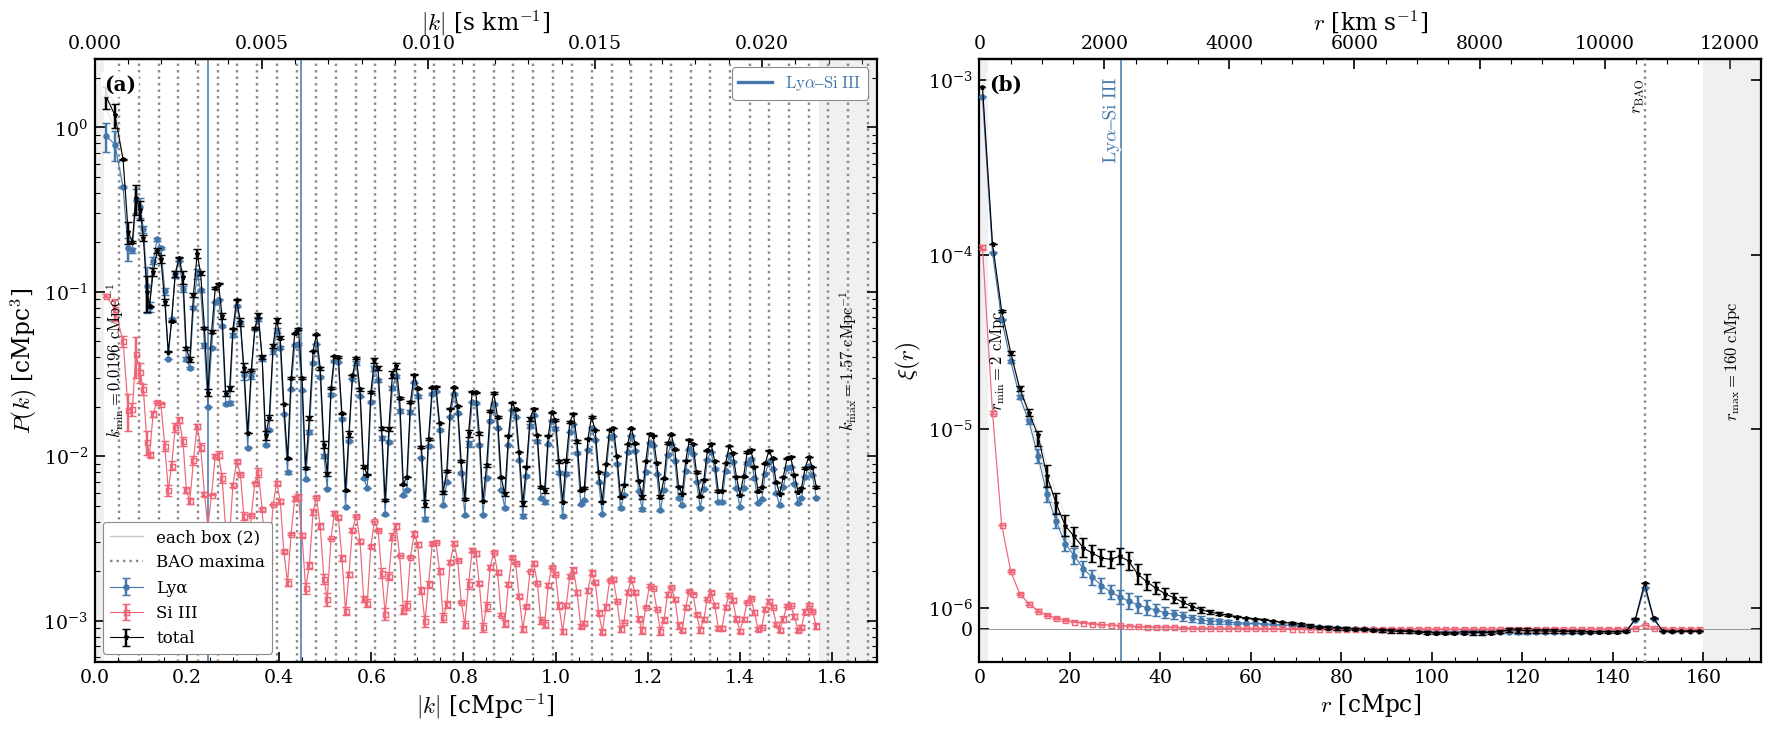

lattice 160 x 320 x 160 per box, a cube of side L = 320 cMpc (v_per = 23164 km/s along the line of sight)
|k| from 0.010 to k_N = 1.571 cMpc^-1 in 194 bins: Nyquist pi N_pix / L = 3.142 cMpc^-1 along the line of sight (pi / dv = 4.34e-02 s/km), pi / (s dx) = 1.571 (x), 1.571 (z) cMpc^-1 across it
|r| up to L / 2 = 160 cMpc in 80 bins of 2.00 cMpc; line-of-sight separations only below the transverse spacing 2.00 cMpc
P_line / P_tot at the lowest |k|: HI-LyA 0.58, SiIII-1206 0.06
BAO peak of r^2 xi above its sidebands at r_BAO -+ 4 sigma_BAO [cMpc^2], against (P_X / P_density at the lowest |k|) x the density's expected 0.450:
           Lyα: r^2 xi(r_BAO) = 0.042, height 0.044 +- 0.000; scaled density 0.028
        Si III: r^2 xi(r_BAO) = 0.004, height 0.005 +- 0.000; scaled density 0.003
         total: r^2 xi(r_BAO) = 0.047, height 0.049 +- 0.000; scaled density 0.049


In [22]:
from skewerjax.summary_stats import bao_height, bao_maxima
BAO_K = bao_maxima(np.pi / dx, window=boxes.grf().bao_window, r_bao=boxes.r_bao)   # the positive maxima of the bump term A_BAO W(k) [cMpc^-1]
fig, axs = plot_overflux_3d(
      f3, ax3, kms_per_cMpc=u, r_bao=boxes.r_bao, delta_v=np.asarray(LINES.delta_v), line_ids=LINE_IDS, box=L_BOX,
      names=NAMES, k_edges=K_EDGES_C, r_edges=R_EDGES_C, limits=lim, quantity="xi", y_scale="symlog", k_scale="linear", bao_k=BAO_K,
      n_harmonics=2
)
add_panel_letters([axs["P"], axs["xi"]])
plt.show()
PT = f3["total"]["P_iso"]
print(f"lattice {n_x} x {N_PIX} x {n_z} per box, a cube of side L = {L_BOX:g} cMpc (v_per = {PERIOD:.0f} km/s along the line of sight)")
print(f"|k| from {ax3['k_edges'][0]:.3f} to k_N = {ax3['k_edges'][-1]:.3f} cMpc^-1 in {ax3['k_edges'].size - 1} bins: Nyquist "
      f"pi N_pix / L = {lim['k_nyq_par']:.3f} cMpc^-1 along the line of sight (pi / dv = {lim['k_nyq_par'] / u:.2e} s/km), "
      f"pi / (s dx) = {lim['k_nyq_perp'][0]:.3f} (x), {lim['k_nyq_perp'][1]:.3f} (z) cMpc^-1 across it")
print(f"|r| up to L / 2 = {lim['r_max']:.0f} cMpc in {ax3['r_edges'].size - 1} bins of {np.diff(ax3['r_edges'])[0]:.2f} cMpc; "
      f"line-of-sight separations only below the transverse spacing {lim['r_perp_min']:.2f} cMpc")
print("P_line / P_tot at the lowest |k|: " + ", ".join(f"{f} {f3[f]['P_iso'][0] / PT[0]:.2f}" for f in LINE_IDS))
r3 = ax3["r_iso"]
d3, d3_th = DENS_STATS["density3d"]["total"], TH_B                    # the density on the same skewers (Part B)
bao_rho = bao_height(r3, r3**2 * d3_th["xi_iso"], boxes.r_bao, boxes.sigma_bao)["height"]
print(f"BAO peak of r^2 xi above its sidebands at r_BAO -+ 4 sigma_BAO [cMpc^2], against (P_X / P_density at the lowest |k|) "
      f"x the density's expected {bao_rho:.3f}:")
for f in (*LINE_IDS, "total"):
    bf = bao_height(r3, r3**2 * f3[f]["xi_iso"], boxes.r_bao, boxes.sigma_bao, r3**2 * f3[f]["xi_iso_err"])
    print(f"  {NAMES[f]:>12}: r^2 xi(r_BAO) = {bf['value']:.3f}, height {bf['height']:.3f} +- {bf['height_err']:.3f}; "
          f"scaled density {f3[f]['P_iso'][0] / d3['P_iso'][0] * bao_rho:.3f}")

**Wedges of the total overflux.** The vertical lines are line-of-sight positions only ($r_\perp = 0$, $\mu = 1$), folded into
$[0, L/2]$: $r_{\rm BAO}$, and for every pair the spot $\Delta v_{ij}/u$ and the crossings of its echoes,
$\lvert r_{\rm BAO} \pm \Delta v_{ij}/u\rvert$, in the styles of the maps: $r_{\rm BAO}$ grey and dotted, and in the pair's colour the spot solid,
the echo $+$ dashed and the echo $-$ dotted. In the other wedges the same features sit elsewhere (the map of D2).

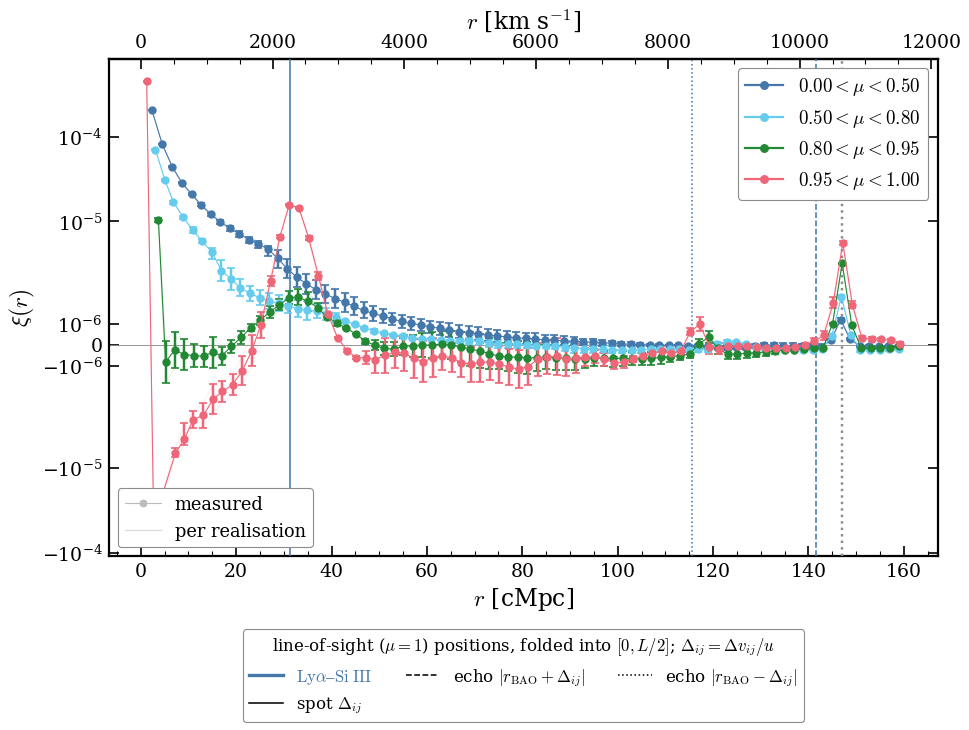

line-of-sight (mu = 1) scales [cMpc], folded into [0, L / 2]: r_BAO 147.0; spot, |r_BAO + Delta|, |r_BAO - Delta| of every pair: Lyα–Si III 31.4, 141.6, 115.6
r^2 xi of the total at r_BAO [cMpc^2]: 0.00 < mu < 0.50: +0.03 +- 0.00; 0.50 < mu < 0.80: +0.05 +- 0.00; 0.80 < mu < 0.95: +0.08 +- 0.00; 0.95 < mu < 1.00: +0.12 +- 0.01


In [23]:
LOS = los_scales(boxes.r_bao, LINE_IDS, np.asarray(LINES.delta_v) / u, L_BOX)   # r_BAO, the spot and the echoes of every pair on the line of sight [cMpc], folded
fig, axs, _ = plot_xi_mu_wedges(tot, r_edges=R_EDGES_C, r_bao=boxes.r_bao, delta_v=np.asarray(LINES.delta_v), line_ids=LINE_IDS, box=L_BOX, kms_per_cMpc=u,
                                quantity="xi", y_scale="symlog")   # the line-of-sight scales of every pair
plt.show()
mu_e, r_mu = ax3["mu_edges"], ax3["r_mu"]
jb = np.nanargmin(np.abs(r_mu - boxes.r_bao), axis=1)
print(f"line-of-sight (mu = 1) scales [cMpc], folded into [0, L / 2]: r_BAO {LOS['ring']:.1f}; spot, |r_BAO + Delta|, |r_BAO - Delta| of every pair: " + "; ".join(
      f"{NAMES_L[p['i']]}–{NAMES_L[p['j']]} {p['spot']:.1f}, {p['plus']:.1f}, {p['minus']:.1f}" for p in LOS["pairs"]))
print("r^2 xi of the total at r_BAO [cMpc^2]: " + "; ".join(
      f"{mu_e[w]:.2f} < mu < {mu_e[w + 1]:.2f}: {r_mu[w, j]**2 * f3['total']['xi_mu'][w, j]:+.2f} +- {r_mu[w, j]**2 * f3['total']['xi_mu_err'][w, j]:.2f}"
      for w, j in enumerate(jb)))

### D4 · P1D next to a DESI measurement

The DESI DR1 P1D at every redshift of Chaves-Montero et al. (Fig. 1; `utils.reference_data`), one colour per $z$, small points
joined by a thin line. The dotted grey lines are the BAO maxima of the 3D spectrum at $k_\parallel = k/u$, for reference: P1D integrates
over $k_\perp$ and damps them. The solid lines, in the colour of each pair $(i, j)$, are the imprint of its separation folded into the
period: the cross term goes as $\cos(k_\parallel\Delta v_{ij})$, with maxima at $k_\parallel = 2\pi n/\Delta v_{ij,\rm fold}$ (`pair_imprint`; the first `N_HARMONICS`
of each pair).

**From 3D to 1D.** With $k_\parallel$, $r_\parallel$ along the line of sight and $\mathbf k_\perp$ across it:

$$
P_{\rm 1D}(k_\parallel) = \int\frac{d^2k_\perp}{(2\pi)^2}\,P_{\rm 3D}(k_\parallel, \mathbf k_\perp)
= \frac{1}{2\pi}\int_{\lvert k_\parallel\rvert}^\infty k\,P(k)\,dk\ \ \text{(isotropic)},\qquad
\xi_{\rm 1D}(r_\parallel) = \xi_{\rm 3D}(r_\perp = 0, r_\parallel) = \int\frac{dk_\parallel}{2\pi}\,e^{ik_\parallel r_\parallel}\,P_{\rm 1D}(k_\parallel).
$$

On the lattice, $P_{\rm 1D}(k_\parallel) = L^{-2}\sum_{\mathbf k_\perp}P(k_\parallel, \mathbf k_\perp)$, the form of
`summary_stats.density._lattice_p1d` (the expectation of the density along the skewers; no P1D expectation is drawn in this
notebook); velocity units through $u$: $k_\parallel\,[\mathrm{s/km}] = k_\parallel\,[\mathrm{cMpc^{-1}}]/u$,
$P_{\rm 1D}\,[\mathrm{km/s}] = u\,P_{\rm 1D}\,[\mathrm{cMpc}]$.

**How they are measured.** P1D and $\xi_{\rm 1D}$ are 1D FFTs of $\delta$ along each skewer, averaged over the
skewers, not derived from the 3D statistics (`summary_stats/lattice.py`: `skewer_p1d`, `skewer_xi1d`; D1, step (d)).
P1D is shown in `K_EDGES_1D`, the scheme of `K_EDGES` along the line of sight (one bin per mode, then steps of
`dk_factor` $\times\,2\pi/v_{\rm per}$, then logarithmic), from $k_{\min} = 2\pi/v_{\rm per}$ to
$k_{\max} = \pi/dv$; a step finer than $2\pi/v_{\rm per}$ holds at most one mode on this axis. $\xi_{\rm 1D}$ is shown
at every lag $r_\parallel = j\,dv$ from 0 to $v_{\rm per}/2$.

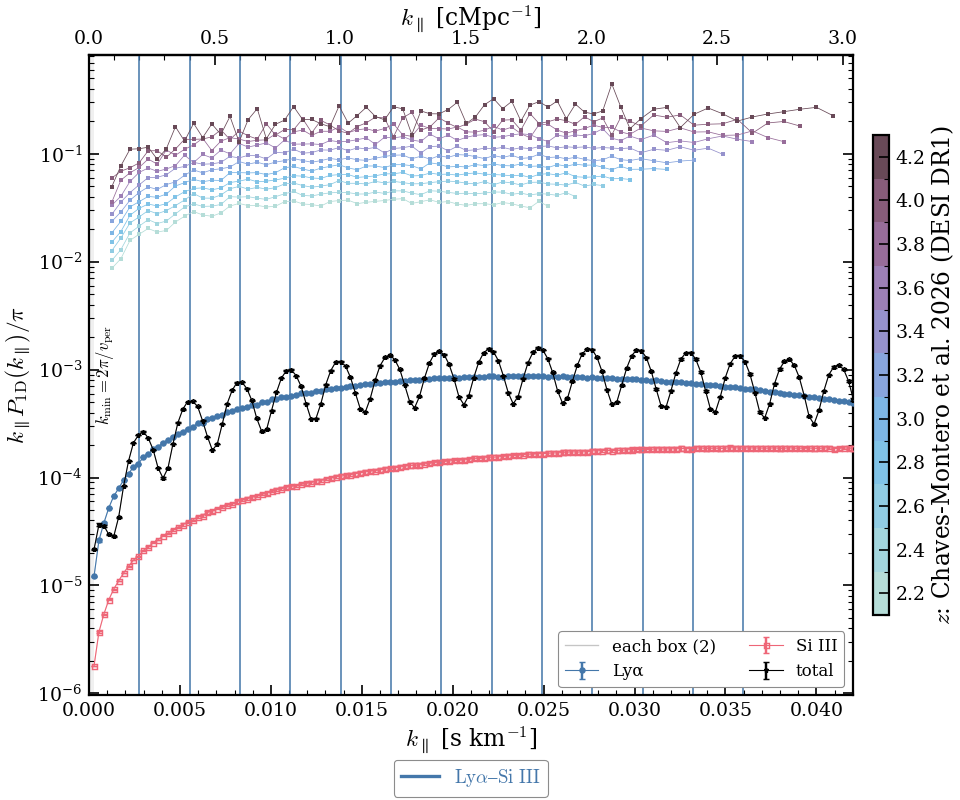

toy z = 2, the 11 reference redshifts 2.2 to 4.2, the nearest z = 2.2; reference / toy (Lya) over its k range: median 54
line separations: periods 2 pi / Delta v [s/km]: Lyα–Si III 0.0028; Nyquist frequency of the cells along the skewers pi / (u dx) = 0.0434 s/km
K_EDGES_1D: 612 bins from 1.36e-04 to 4.34e-02 s/km, 160 hold a mode (at most 1 each); k_min = 2 pi / v_per = 2.71e-04, k_max = pi / dv = 4.34e-02 s/km


In [28]:
from skewerjax.summary_stats import bao_k_edges
N_HARMONICS = 13                                                     # the first maxima of every pair's imprint on the P1D figures (all of them would be 100-200 lines)
from skewerjax.utils.plotting import plot_p1d_reference
from skewerjax.utils.reference_data import P1D_DESI_DR1, nearest_reference
P1D_REF = nearest_reference(P1D_DESI_DR1, boxes.z)                               # the reference nearest to the box's z, for the print (every z is drawn alike)
K_EDGES_1D = bao_k_edges(2 * np.pi / PERIOD, np.pi / DV, K_INFO["k_w"] / u, k_1=None, dk_factor=0.25, n_log=12)  # [s/km]: as K_EDGES
BAO_K_1D = bao_maxima(P1D_REF["k_max_figure"] * u, window=boxes.grf().bao_window, r_bao=boxes.r_bao, kms_per_cMpc=u)  # k_par = k / u of the 3D maxima [s/km]
fig, ax = plot_p1d_reference(
      P1D, P1D_DESI_DR1, names=NAMES, k_max=P1D_REF["k_max_figure"], k_edges=K_EDGES_1D,
      k_limits=(2 * np.pi / PERIOD, np.pi / DV), kms_per_cMpc=u, bao_k=None,
      delta_v=np.asarray(LINES.delta_v), line_ids=LINE_IDS, n_harmonics=N_HARMONICS
)
plt.show()
kc = P1D["k"]
toy = np.interp(P1D_REF["k"], kc, kc * P1D["p1d"][0] / np.pi)
print(f"toy z = {boxes.z:g}, the {len(P1D_DESI_DR1)} reference redshifts {min(P1D_DESI_DR1):g} to {max(P1D_DESI_DR1):g}, the nearest z = {P1D_REF['z']:g}; reference / toy (Lya) over its k range: "
      f"median {np.median(P1D_REF['kP_pi'] / toy):.0f}")
print("line separations: periods 2 pi / Delta v [s/km]: " + ", ".join(f"{NAMES_L[p['i']]}–{NAMES_L[p['j']]} {2 * np.pi / p['dv']:.4f}" for p in PAIRS) + "; "
      f"Nyquist frequency of the cells along the skewers pi / (u dx) = {np.pi / (u * boxes.dx):.4f} s/km")
occ = np.histogram(kc[1:], K_EDGES_1D)[0]
print(f"K_EDGES_1D: {K_EDGES_1D.size - 1} bins from {K_EDGES_1D[0]:.2e} to {K_EDGES_1D[-1]:.2e} s/km, {np.sum(occ > 0)} hold a mode "
      f"(at most {occ.max()} each); k_min = 2 pi / v_per = {2 * np.pi / PERIOD:.2e}, k_max = pi / dv = {np.pi / DV:.2e} s/km")

### D5 · The decomposition by order

The decomposition is computed only here, by the explicit call `decompose_1d` of the next code cell (opt-in; step (e)).

**The terms.** `DeltaFieldBuilder` also forms, per skewer, the products $\delta_A = \prod_{j \in A}\delta_j$ of every
subset $A$ of lines. With $\mathcal C$, the means of the products over the set of pixels of the mean transmission, $\mathcal C = \langle\delta_1\delta_2\rangle$
for two lines (plus the higher orders for more), the total overflux decomposes **exactly** into them (review notes, Sec.
Overflux, with the mean of the ensemble):

$$
\delta_{\rm tot} = \frac{\sum_j\delta_j + \sum_{j_1 < j_2}\delta_{j_1}\delta_{j_2} + \cdots - \mathcal C}{1 + \mathcal C},\qquad
\mathcal C = \sum_{\lvert A\rvert \ge 2}\langle\delta_A\rangle = \frac{\bar T}{\prod_j \bar T_j} - 1.
$$

It follows from $T = \prod_j \bar T_j(1 + \delta_j)$ and its mean over the same set,
$\bar T = \prod_j \bar T_j\,\bigl(1 + \sum_j\langle\delta_j\rangle + \mathcal C\bigr)$. The order-1 term of the
denominator, $\sum_j\langle\delta_j\rangle$, vanishes because every $\bar T_j$ and $\bar T$ are
means over the same set of pixels (every mode of `mean`). With the default `"redshift"`, $\mathcal C(v)$ is
$\langle\delta_1\delta_2\rangle$ at each pixel over the ensemble (one number with `"global"`, one per box with `"box"`,
one per skewer with `"skewer"`; Part C prints the largest difference, at machine precision), and the sum of the terms
reproduces $\delta_{\rm tot}$ at every pixel of every skewer to machine precision (printed).
`OverfluxStatistics1D` gives P1D and $\xi_{\rm 1D}$ of the total, of every pair of terms $(A, B)$ and of every order
$\lvert A\rvert + \lvert B\rvert$: order $n$ collects the terms with $\lvert A\rvert + \lvert B\rvert = n$, order 0 is the
normalisation term $\mathcal C$, and the orders add up to the total to machine precision (printed).

**The terms of two lines** (the example; four lines add every subset, orders up to 8). With two lines, at each pixel,

$$
T = \bar T_1 \bar T_2\, (1 + \delta_1)(1 + \delta_2),\qquad
\delta = \frac{\delta_1 + \delta_2 + \delta_1\delta_2 - \mathcal C}{1 + \mathcal C},\qquad \mathcal C = \langle \delta_1 \delta_2 \rangle.
$$

Every term of $\xi_{\rm 1D}$ (real space) or P1D (Fourier space) is a pair of subsets $A, B$ of $\{1, 2\}$ (or the
normalisation term), of order $\lvert A\rvert + \lvert B\rvert$:

| $A \backslash B$ | $\mathcal{C}$ (order 0) | 1 (order 1) | 2 (order 1) | 12 (order 2) |
|---|---|---|---|---|
| $\mathcal{C}$ | $+\mathcal{C}\mathcal{C}$ | 0 | 0 | $-\mathcal{C}\mathcal{C}$ |
| 1 | 0 | $\xi_{11}$, $P_{11}$ | $\xi_{21}$, $P_{21}$ | $\xi_{(12)1}$, $P_{(12)1}$ |
| 2 | 0 | $\xi_{12}$, $P_{12}$ | $\xi_{22}$, $P_{22}$ | $\xi_{(12)2}$, $P_{(12)2}$ |
| 12 | $-\mathcal{C}\mathcal{C}$ | $\xi_{1(12)}$, $P_{1(12)}$ | $\xi_{2(12)}$, $P_{2(12)}$ | $\xi_{(12)(12)}$, $P_{(12)(12)}$ |

The zeros are exact after the ensemble average, because $\langle\delta_j\rangle = 0$ over the set of the mean
(here at each pixel): a pair $(\mathcal C, j)$ is $-\mathcal C$ times the mean of $\delta_j$ along the skewer in
$\xi_{\rm 1D}$, and lives at $k = 0$ alone in P1D. The ensemble average gives

$$
\xi = \frac{-\mathcal{C}^2 + \xi_{11} + \xi_{22} + \xi_{12,{\rm sym}} + \xi_{1(12),{\rm sym}} + \xi_{2(12),{\rm sym}} + \xi_{(12)(12)}}{(1 + \mathcal C)^2},
$$

$$
P(k) = \frac{P_{11} + P_{22} + P_{12,{\rm sym}} + P_{1(12),{\rm sym}} + P_{2(12),{\rm sym}} + P_{(12)(12)} - 2\pi\,\mathcal C^2\, \delta_D(k)}{(1 + \mathcal C)^2},
$$

where "sym" adds the pair and its transpose: 1/2 with 2/1, 1/12 with 12/1, and 2/12 with 12/2 (written for a constant
$\mathcal C$). With the default `"redshift"`, $\mathcal C(v)$ varies slowly along the skewer, with the mean
transmission, and the code weights every term at its own pixel by $1/(1 + \mathcal C(v))$, which keeps the
decomposition exact.

For a second line that is a shifted copy of the first, $\delta_2(v) \propto \delta_1(v - \Delta v_{\mathrm{Ly}\alpha\text{–Si III}})$, the cross term is
$P_{12,{\rm sym}} \propto 2\cos(k\Delta v_{\mathrm{Ly}\alpha\text{–Si III}})\, P_{11}$. It oscillates with period $2\pi/\Delta v_{\mathrm{Ly}\alpha\text{–Si III}}$ in $k$ (D4, and
the cross terms of D6): the Fourier image of the $\xi_{\rm 1D}$ peak at $\Delta v_{\mathrm{Ly}\alpha\text{–Si III}}$.

**By order.** Order 2 holds the Gaussian-like products and dominates; orders 3 to $2N$ ($N$ = 4 lines) are the non-linear
corrections of the products of the lines. The line separations $\Delta v_{i\text{–}j}$, folded into the period (solid, each pair in its colour and named by its line; C1 prints them), are where
the cross terms put a peak in $\xi_{\rm 1D}$; in P1D they oscillate as $\cos(k\Delta v_{\mathrm{Ly}\alpha\text{–Si III}})$, with period $2\pi/\Delta v_{\mathrm{Ly}\alpha\text{–Si III}}$
in $k$ (printed below in units of the mode spacing), and the solid lines are their maxima, $k = 2\pi n/\Delta v_{ij,\rm fold}$. The top axes give $k_\parallel$ and the separation in comoving units
(factor $u$).

**(e) The decomposition by order, optional.** `decompose_1d` splits P1D and $\xi_{\rm 1D}$ of the total into the
pairs of subset terms and their orders. It needs the products of the lines at every pixel, so it costs more than the
plain statistics of (d) and is needed only here: it is called explicitly, not by default.

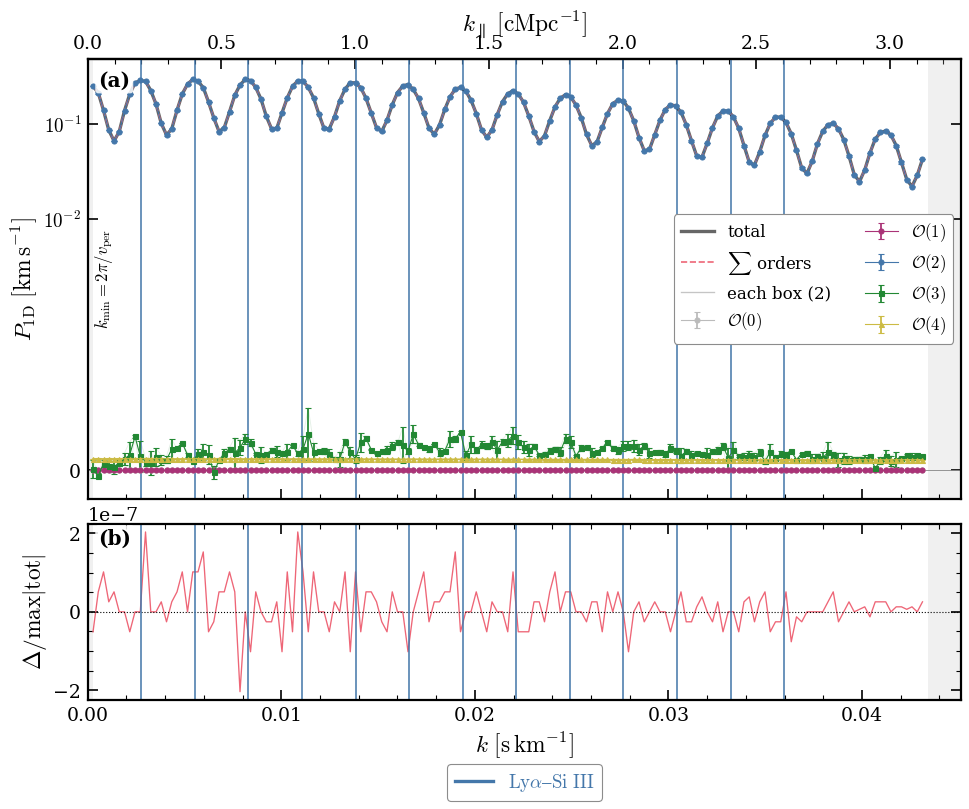

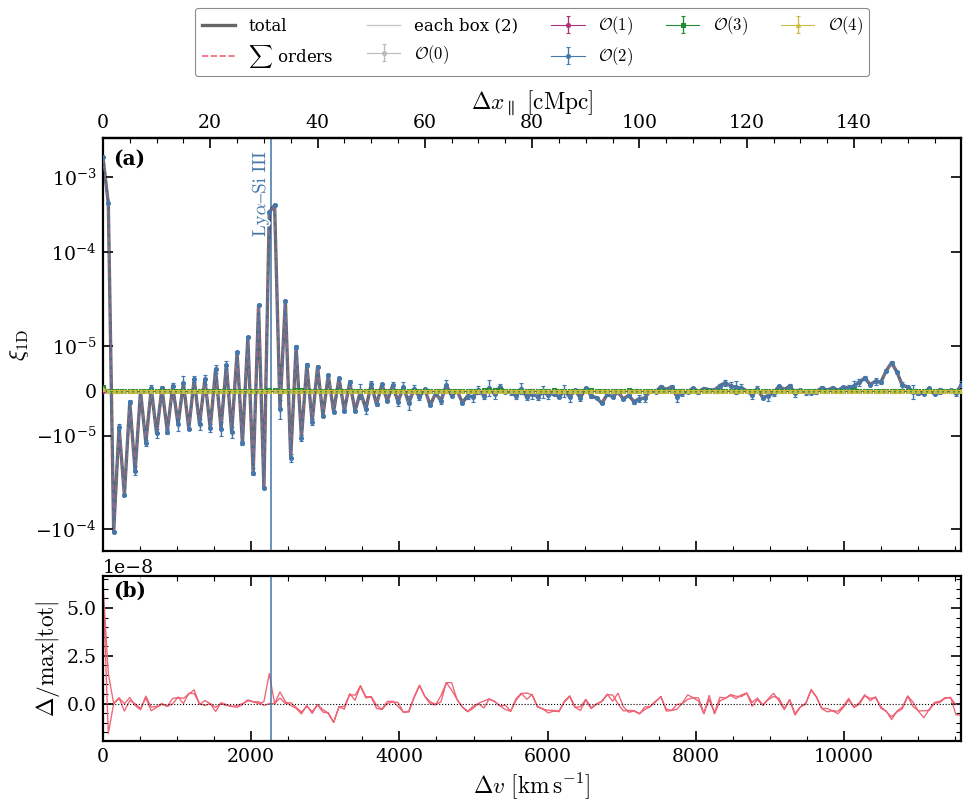

max |sum of the orders - total| / max |total|: P 2.0e-07, xi 6.3e-08; at every pixel: max |[sum_A delta_A - C] / (1 + C) - delta_tot| = 4.0e-08; order 1 / max |total|: P 1.9e-09
the total of the decomposition against the per-skewer statistics of D1 (d): P1D 2.7e-07, xi1D 1.4e-07 (relative)
orders: 0, 1, 2, 3, 4 (2 lines: 0 .. 2 N_lines); cos(k Delta v) of Si III - Lya: period 2 pi / Delta v = 2.77e-03 s/km = 10.20 mode spacings (2 pi / period)


In [25]:
from skewerjax.summary_stats import decompose_1d, ensemble_1d
from skewerjax.utils.plotting import plot_p1d_orders, plot_xi1d_orders
FLUX_ORDERS = ensemble_1d([decompose_1d(TAU[i], DV, T_BAR[i], mean=MEAN) for i in range(n_box)])  # (e), opt-in
dv_lines = np.asarray(LINES.delta_v)                                             # the offsets of every line: every pair's separation
K_LIMITS_1D = (2 * np.pi / PERIOD, np.pi / DV)                                   # k_min, k_max of the line of sight [s/km]
fig, axs = plot_p1d_orders(FLUX_ORDERS, k_edges=K_EDGES_1D, k_limits=K_LIMITS_1D, kms_per_cMpc=u, k_scale="linear", delta_v_list=dv_lines, line_ids=LINE_IDS, n_harmonics=N_HARMONICS)
add_panel_letters(axs)
plt.show()
fig, axs = plot_xi1d_orders(FLUX_ORDERS, delta_v_list=dv_lines, line_ids=LINE_IDS, kms_per_cMpc=u, y_scale="symlog")  # every lag, 0 .. v_per / 2 (quantity="r2xi", y_scale="symlog": other views)
add_panel_letters(axs)
plt.show()
e = FLUX_ORDERS
print(f"max |sum of the orders - total| / max |total|: P {np.abs(e['P_order'].sum(0) - e['P_total']).max() / np.abs(e['P_total']).max():.1e}, "
      f"xi {np.abs(e['xi_order'].sum(0) - e['xi_total']).max() / np.abs(e['xi_total']).max():.1e}; at every pixel: "
      f"max |[sum_A delta_A - C] / (1 + C) - delta_tot| = {CHECK['decomposition_error']:.1e}; order 1 / max |total|: "
      f"P {np.abs(e['P_order'][1]).max() / np.abs(e['P_total']).max():.1e}")
xi_c, xi_d = e["xi_total"][N_PIX // 2:], XI1D["xi1d"][-1][: N_PIX // 2]  # the lags 0 .. v_per / 2 - dv (centred lags: 0 at N_PIX / 2)
print(f"the total of the decomposition against the per-skewer statistics of D1 (d): P1D {np.abs(e['P_total'] - P1D['p1d'][-1]).max() / P1D['p1d'][-1].max():.1e}, "
      f"xi1D {np.abs(xi_c - xi_d).max() / np.abs(xi_d).max():.1e} (relative)")
print("orders: " + ", ".join(str(n) for n in range(e["P_order"].shape[0])) + f" ({len(LINE_IDS)} lines: 0 .. 2 N_lines); cos(k Delta v) of Si III - "
      f"Lya: period 2 pi / Delta v = {2 * np.pi / abs(dv_12):.2e} s/km = {PERIOD / abs(dv_12):.2f} mode spacings (2 pi / period)")

### D6 · Each order, term by term

The same decomposition one level down, one row per order. Every term $(A, B)$ of an order is drawn with its transpose
$(B, A)$ as A–B (their sum, which is real), on the order's total (the thick line). The lines are numbered 1 to 4 (`LINE_IDS`, written in the first legend of the P1D figure). Order 2 holds the products $j$–$j$, the cross
terms $i$–$j$ and the normalisation cross terms $\mathcal{C}$–$ij$; orders 3 to 8 the products with the subsets of two or more
lines. With four lines an order holds up to 28 terms: the six largest are drawn (`max_terms`; `terms=` selects others), the
rest summed (grey dashed). The
order-0 term $\mathcal{C}$–$\mathcal{C}$ is not shown: it is nearly constant in $\xi_{\rm 1D}$, and lives at the lowest
$k$ in P1D.

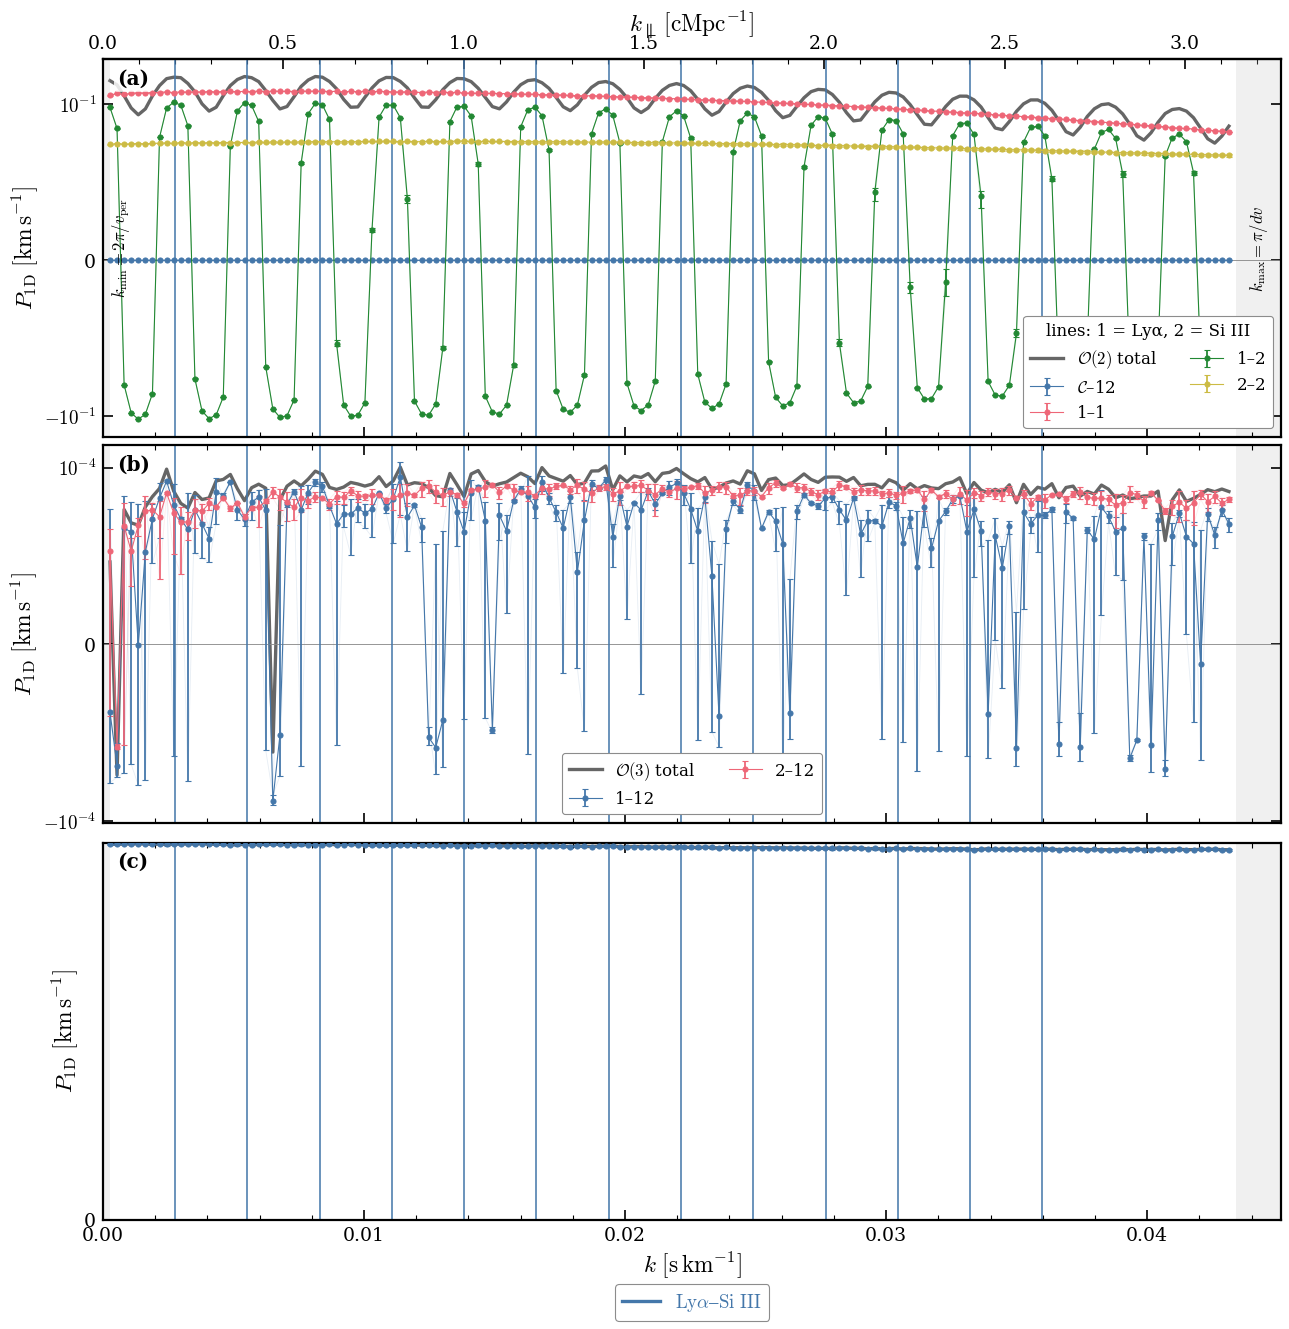

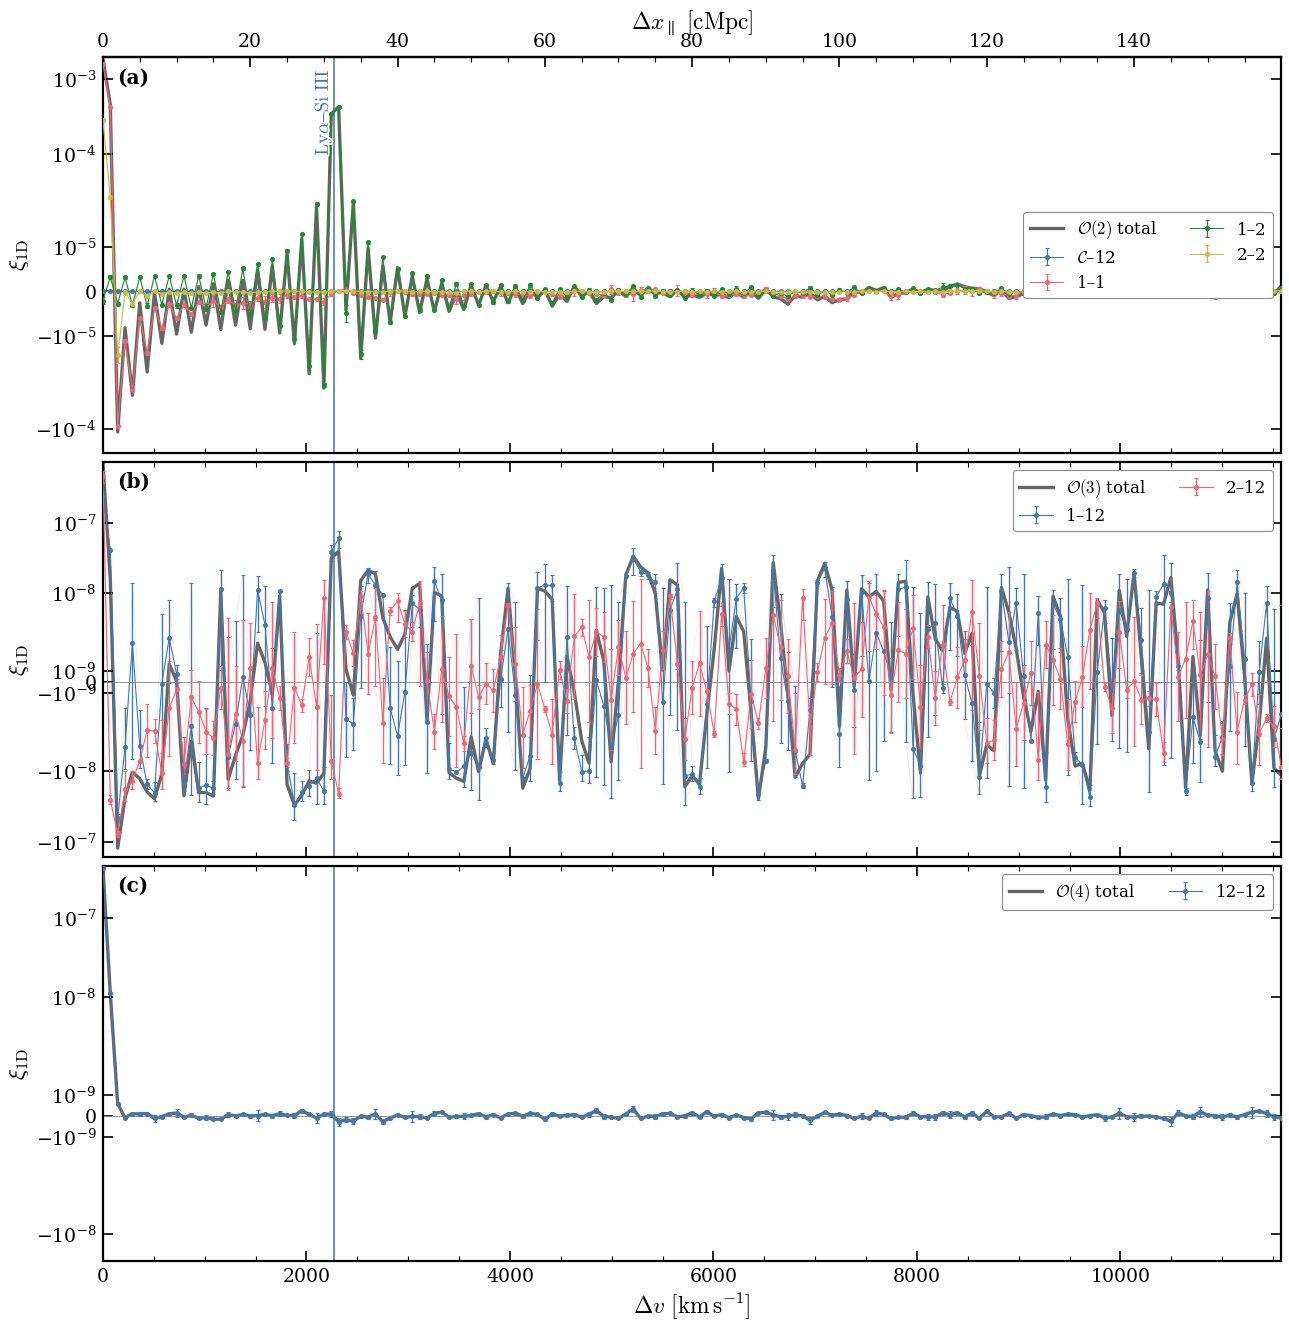

In [26]:
from skewerjax.utils.plotting import plot_p1d_terms, plot_xi1d_terms
fig, axs = plot_p1d_terms(FLUX_ORDERS, k_edges=K_EDGES_1D, k_limits=K_LIMITS_1D, kms_per_cMpc=u, line_ids=LINE_IDS, k_scale="linear", delta_v_list=dv_lines, n_harmonics=N_HARMONICS)  # the largest terms of each order
add_panel_letters(axs)
plt.show()
fig, axs = plot_xi1d_terms(FLUX_ORDERS, delta_v_list=dv_lines, kms_per_cMpc=u, line_ids=LINE_IDS, y_scale="symlog")  # the separations, folded: solid, in the pairs' colours
add_panel_letters(axs)
plt.show()